

# **Engineering Statistics and Probability**
## **Computer Assignment 5**
---

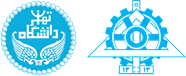

[**School of Electrical and Computer Engineering**, **College of Engineering**, **University of Tehran**](https://ece.ut.ac.ir/)

**Instructors:** Dr. Bahrak, Dr. Vahhabi


## **Topic:** Sum of Random Variables, Conditional Distribution, Covariance, and Functions of Two Random Variables

### **Submission Date:**

---

### We will use the following R packages:

*   [`dplyr`](https://cran.r-project.org/web/packages/dplyr/vignettes/dplyr.html): A popular and easy-to-use package for data manipulation in R. (for Qestion 2)
*   [`ggplot2`](https://ggplot2.tidyverse.org/): A powerful package for creating visualizations in R.
*   [`magrittr`](https://magrittr.tidyverse.org) : An package that introduces the pipe operator (%>%) to make code more readable by chaining

+ ⚠️ **Remove comment lines on first run.**


In [70]:
# install.packages("magrittr")
# install.packages("dplyr")
# install.packages("ggplot2")
library(magrittr)
library(dplyr)
library(ggplot2)
set.seed(42)
options(repr.plot.width = 15, repr.plot.height = 6)

# Question 1
## Sum of RVs and function of two RVs ⭐

A company wants to obtain a distribution of the loss it will incur at the end of the upcoming week.

Suppose a company is losing money due to product returns. The number of products of type `a` and `b` returned to the company each day is exponentially distributed and independent of each other, and the company loses 1\$ for each product returned.
Let $X_i$ number of products of type `a` and $Y_i$ number of products of type `b` be returned on day i.

 $$X_i , Y_i \sim Exp(λ = 0.01)$$

### 0. Complete the following two functions to plot the histogram and PDF of the data.

+ Note: You can use `geom_density` to plot the PDF.

In [72]:
plot_hist <- function(data, bins = 30, fill_color = "skyblue", line_color = "white") {
  ggplot(data.frame(x = data), aes(x = x)) +
    geom_histogram(
      bins = bins,
      fill = fill_color,
      color = line_color
    ) +
    labs(
      title = "Histogram",
      x = "Value",
      y = "Frequency"
    ) +
    theme_minimal()
}

plot_pdf <- function(data, line_color = "blue", fill_color = "lightblue", alpha = 0.5) {
   ggplot(data.frame(x = data), aes(x = x)) +
    geom_density(
      color = line_color,
      fill = fill_color,
      alpha = alpha
    ) +
    labs(
      title = "Probability Density Function (PDF)",
      x = "Value",
      y = "Density"
    ) +
    theme_minimal()
}

### 1. Write down the company's loss due to the return of product A after one week. Let's assume this value is equal to $D$.

### 2. By generating 100,000 samples of the loss each day caused by product a, obtain 100,000 samples of the $D$. Then plot its PDF and histogram.



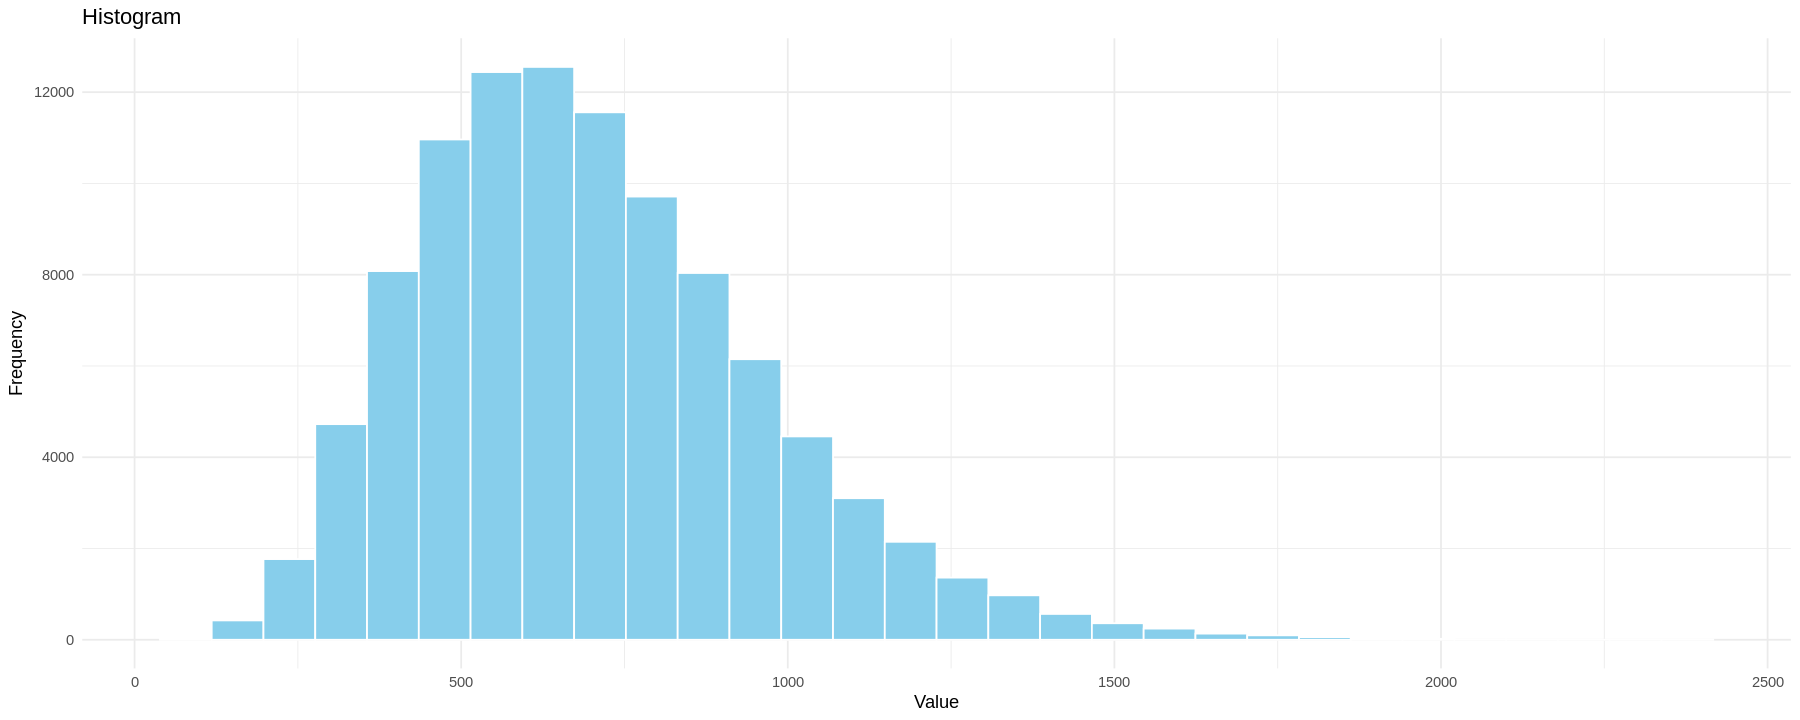

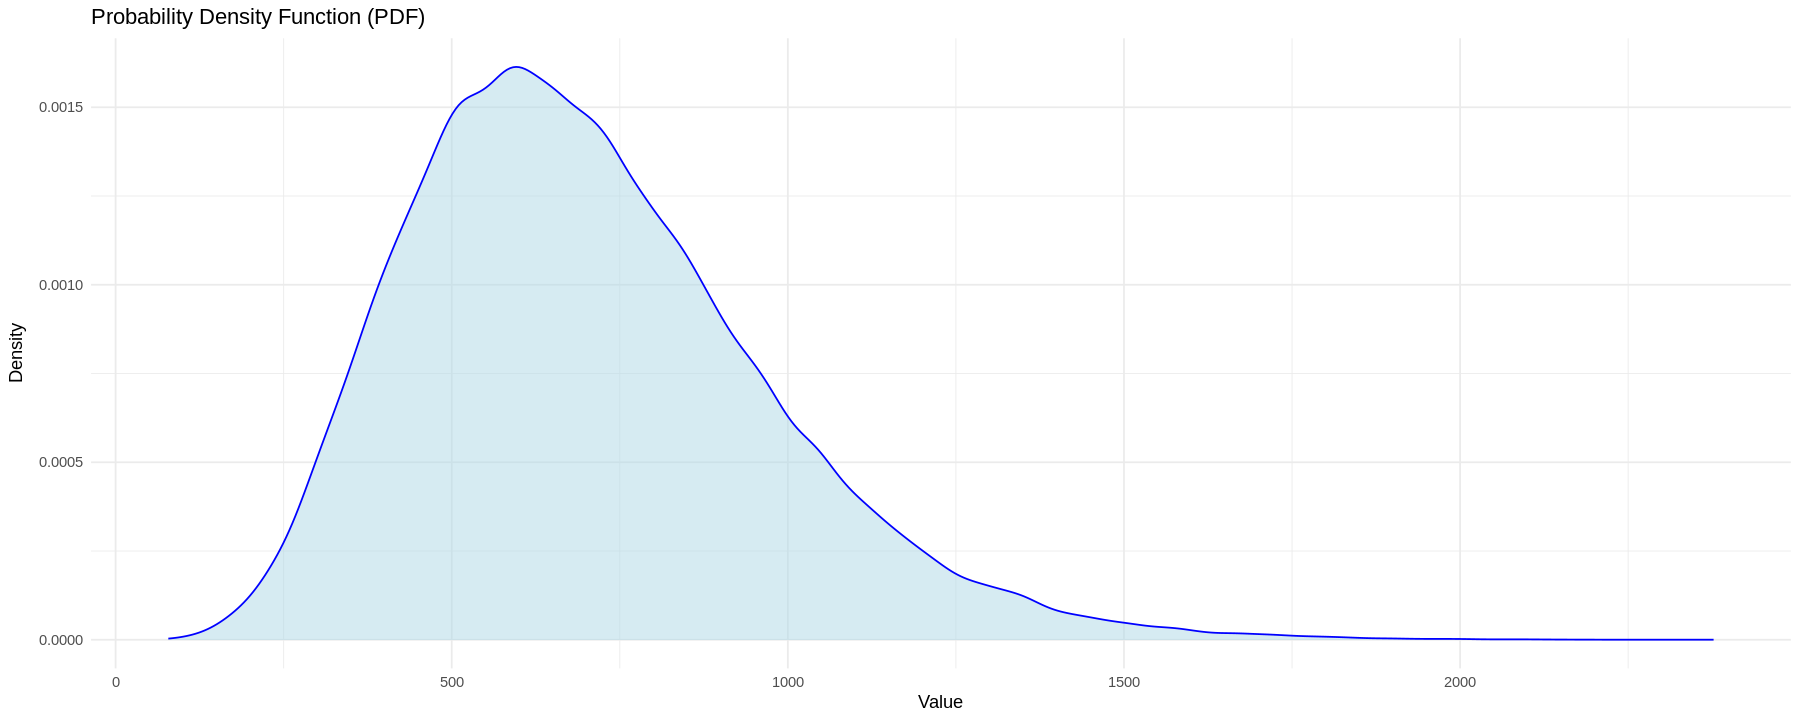

In [73]:
 n_samples <- 100000
lambda <- 0.01
days <- 7

D <- replicate(n_samples, sum(rexp(days, rate = lambda)))

plot_hist(D)
plot_pdf(D)


### 3. Calculate the mean and variance of the resulting distribution.

In [74]:
mean_D <- mean(D)
var_D <- var(D)

mean_D
var_D


[1] 699.8784

[1] 69905.76

The total loss of the company after `n` days is the sum of `n` identical and independent exponential variables.
This sum has a distribution called the [**gamma distribution**](https://en.wikipedia.org/wiki/Gamma_distribution)

### 4. By studying this distribution, obtain the gamma distribution parameters for D and plot it's PDF.

In [75]:
plot_pdf_theory <- function(x, y,
                    line_color = "blue",
                    line_size = 1,
                    title = "Plot",
                    xlab = "x",
                    ylab = "y") {
  ggplot(data.frame(x, y), aes(x, y)) +
    geom_line(color = line_color, size = line_size) +
    theme_minimal() +
    labs(title = title, x = xlab, y = ylab)
}

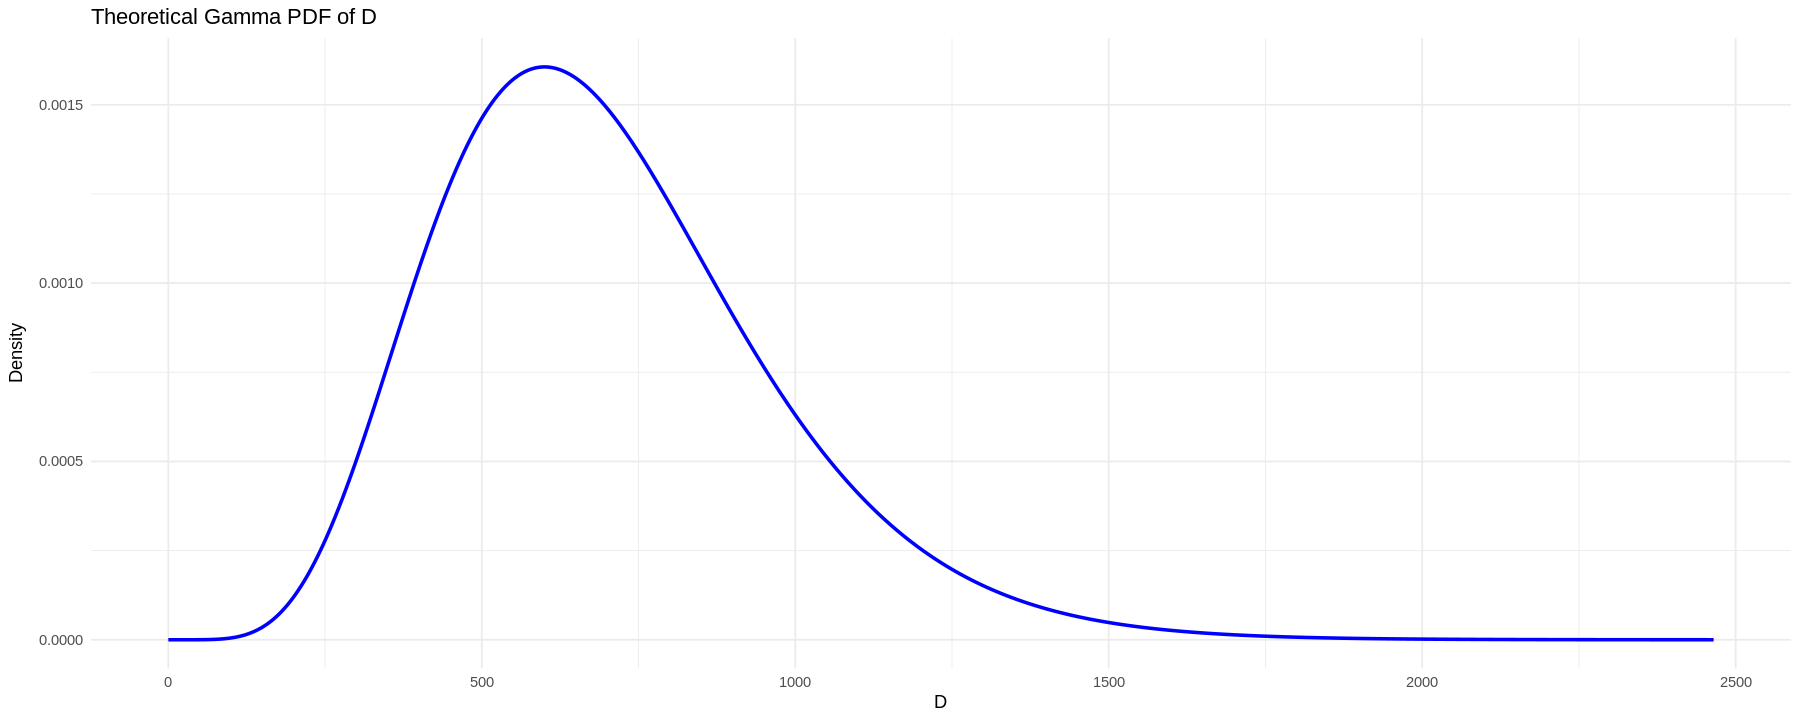

In [76]:
shape <- 7
rate <- 0.01

n_samples <- 100000
days <- 7

D <- replicate(n_samples, sum(rexp(days, rate = rate)))

x_vals <- seq(0, max(D), length.out = 1000)
y_vals <- dgamma(x_vals, shape = shape, rate = rate)

plot_pdf_theory(
  x = x_vals,
  y = y_vals,
  title = "Theoretical Gamma PDF of D",
  xlab = "D",
  ylab = "Density"
)


### 5. Calculate the mean and variance theoretically and compare with section 3.

In [77]:

theoretical_mean_D <- shape / rate
theoretical_var_D  <- shape / (rate^2)

theoretical_mean_D
theoretical_var_D


[1] 700

[1] 70000

Now suppose the company wants to know what percentage of the company's loss after 7 days is related to product a.

### 6. Write down this ratio. plot 100,000 samples of this ratio by generating random samples of the company's losses. Also calculate the mean and variance of the data.

This new distribution is called the [**beta distribution**](https://en.wikipedia.org/wiki/Beta_distribution).

In [78]:

n_samples <- 100000
lambda <- 0.01
days <- 7

D_A <- replicate(n_samples, sum(rexp(days, rate = lambda)))
D_B <- replicate(n_samples, sum(rexp(days, rate = lambda)))

R <- D_A / (D_A + D_B)

mean_R <- mean(R)
var_R  <- var(R)

mean_R
var_R


[1] 0.5004379

[1] 0.01661005

### 7. By studying this distribution, calculate its parameters, then theoretically estimate its mean and variance and compare it with Section 6.

In [79]:

alpha <- 7
beta <- 7

theoretical_mean_R <- alpha / (alpha + beta)
theoretical_var_R  <- (alpha * beta) / ((alpha + beta)^2 * (alpha + beta + 1))

theoretical_mean_R
theoretical_var_R


[1] 0.5

[1] 0.01666667

### 8. Plot the PDF graph of the resulting beta distribution and compare it with the histogram in Section 6.

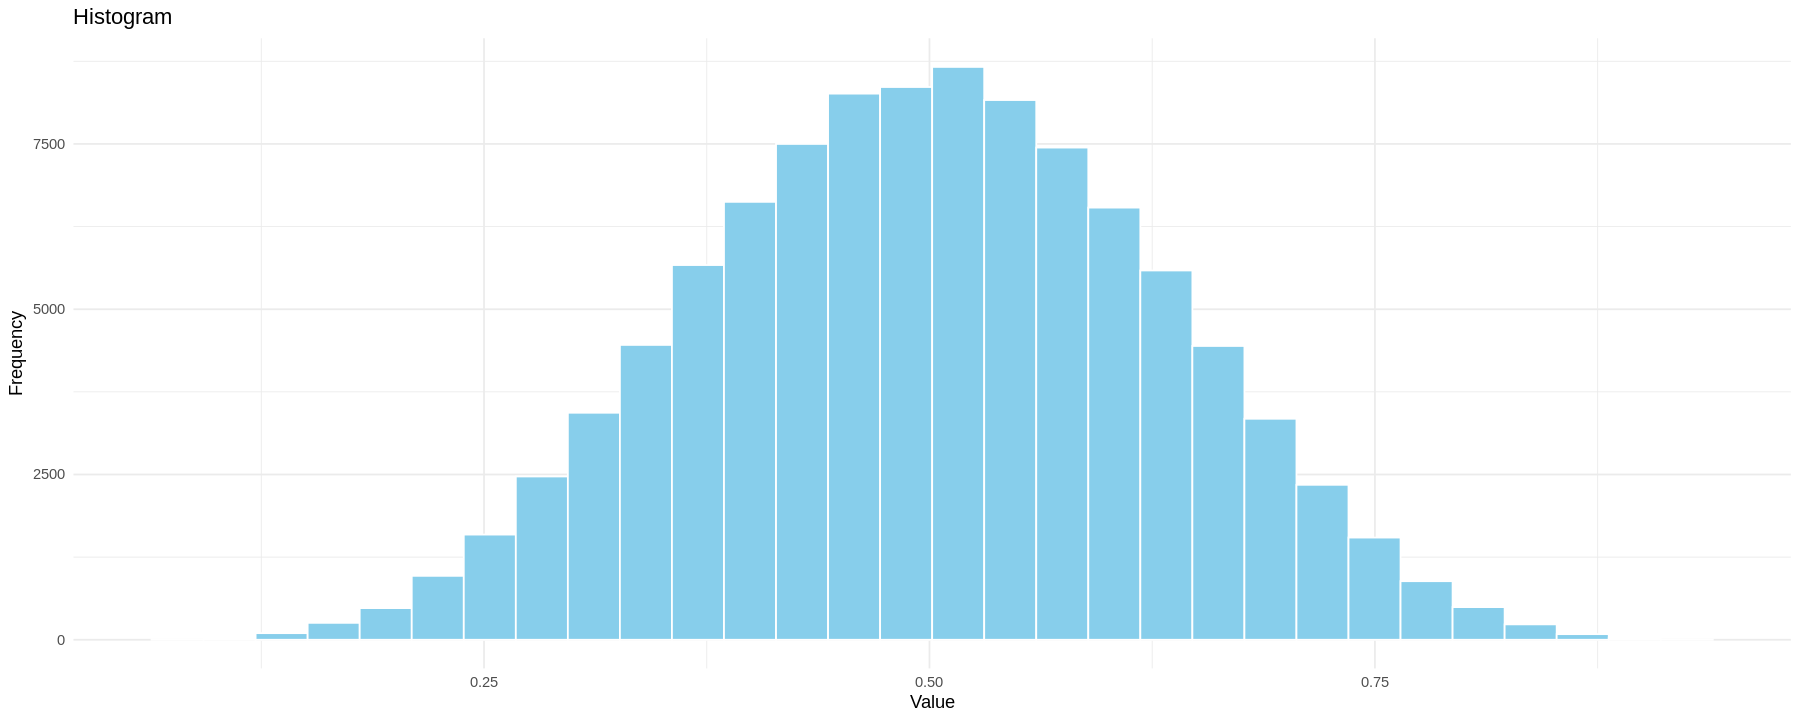

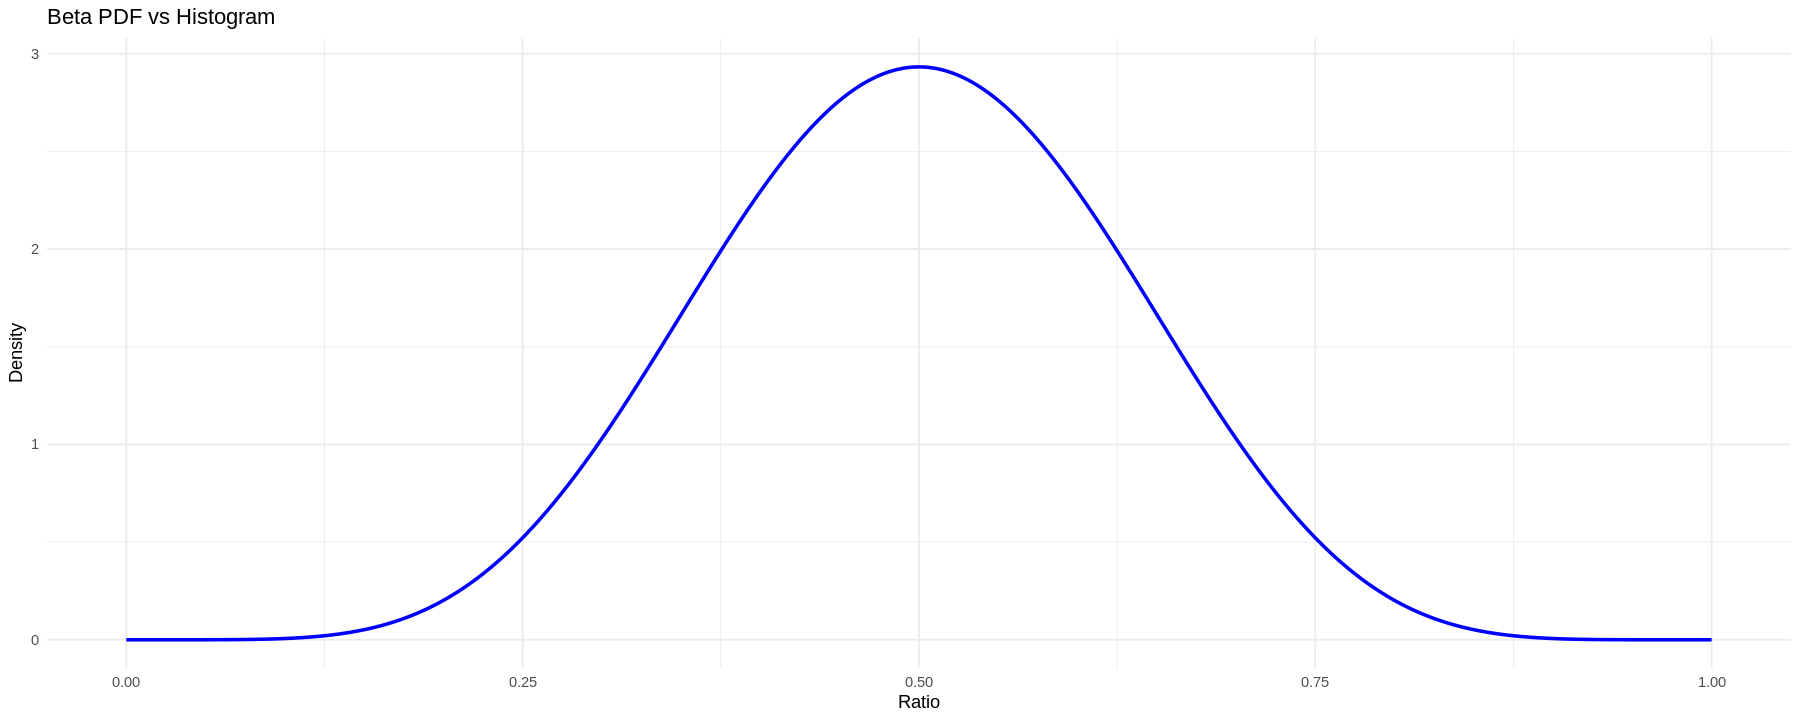

In [80]:
 beta <- 7

x_vals <- seq(0, 1, length.out = 1000)
y_vals <- dbeta(x_vals, shape1 = alpha, shape2 = beta)

plot_hist(R)
plot_pdf_theory(
  x = x_vals,
  y = y_vals,
  title = "Beta PDF vs Histogram",
  xlab = "Ratio",
  ylab = "Density"
)


### 9. Now suppose the company wants to calculate the same ratio for a day instead of a week. Re-simulate this ratio.
### 10. What distribution does the resulting distribution resemble? Verify this with theoretical calculations.

In [81]:
#Q9
n_samples <- 100000
lambda <- 0.01

D_A_day <- rexp(n_samples, rate = lambda)
D_B_day <- rexp(n_samples, rate = lambda)

R_day <- D_A_day / (D_A_day + D_B_day)

mean(R_day)
var(R_day)


[1] 0.5007921

[1] 0.08355519

In [82]:
 #Q10
alpha_day <- 1
beta_day <- 1

theoretical_mean_day <- alpha_day / (alpha_day + beta_day)
theoretical_var_day  <- (alpha_day * beta_day) /
  ((alpha_day + beta_day)^2 * (alpha_day + beta_day + 1))

theoretical_mean_day
theoretical_var_day


[1] 0.5

[1] 0.08333333

# Question 2
## Covariance 🌡️

We will use the built-in **airquality** dataset in R, which contains weather data for New York in 1970.

We will focus on the **Day**, **Month**, and **Temp** columns. To represent the progression of the year, we will define a new variable called **Day Number**, which indicates the number of days passed since the beginning of the year.


## Familiarize With Dataset 🌦️ (7.5 points🎯)

### 1. Plot the temperature (**Temp**) against the **Day Number**. This will help you become familiar with the dataset and observe the general trend of temperature throughout the year.

In [83]:
head(airquality)


,Ozone,Solar.R,Wind,Temp,Month,Day,Day_Number
,<int>,<int>,<dbl>,<int>,<int>,<int>,<dbl>
1,41,190,7.4,67,5,1,32
2,36,118,8.0,72,5,2,33
3,12,149,12.6,74,5,3,34
4,18,313,11.5,62,5,4,35
5,NA,NA,14.3,56,5,5,36
6,28,NA,14.9,66,5,6,37


`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


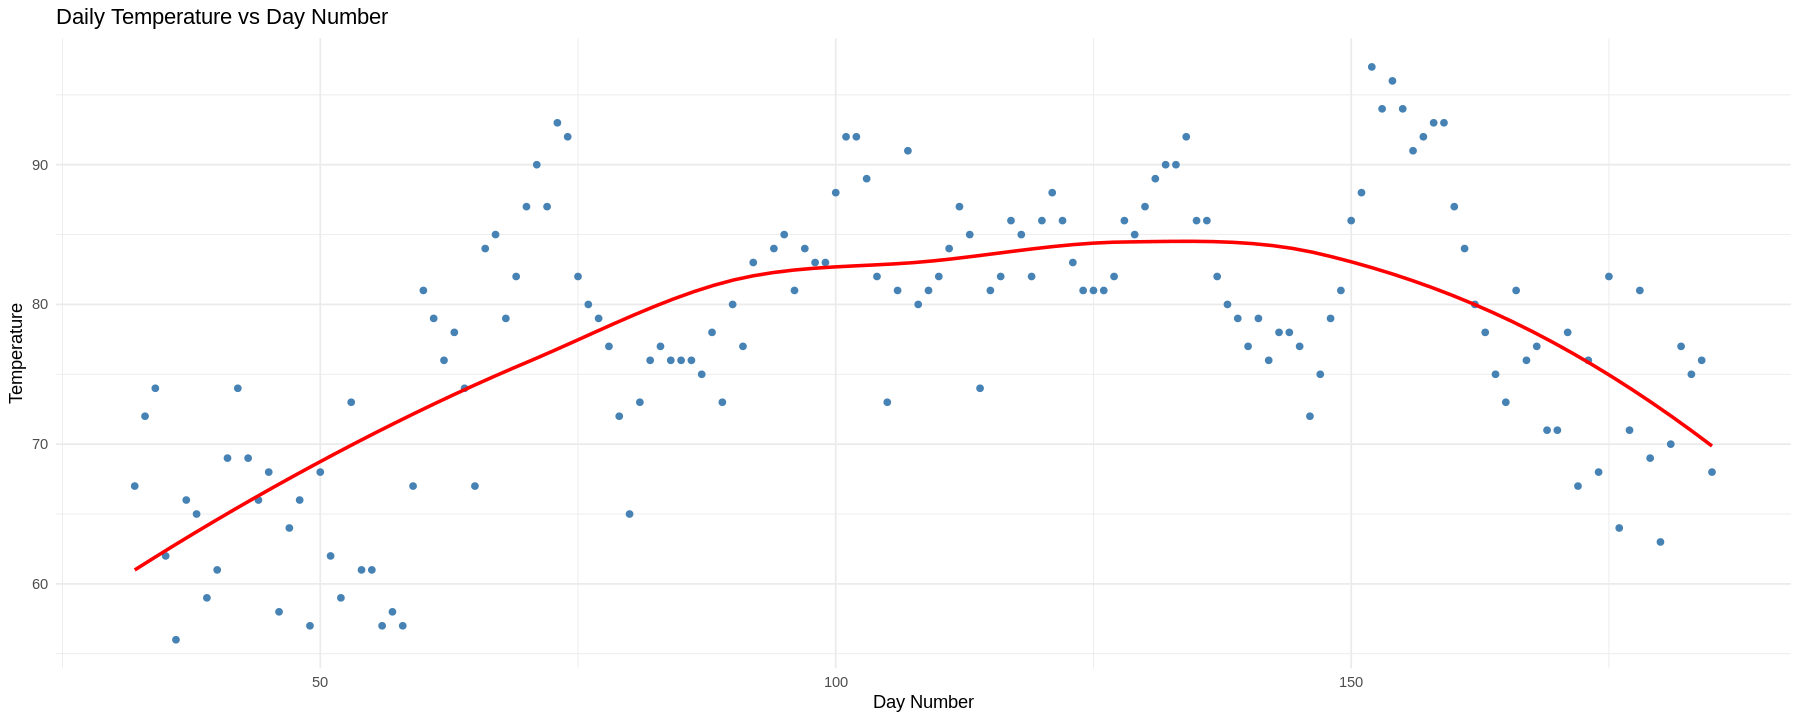

In [84]:
airquality <- airquality %>%
  mutate(Day_Number = as.numeric(factor(Month)) * 31 + Day)

ggplot(airquality, aes(x = Day_Number, y = Temp)) +
  geom_point(color = "steelblue") +
  geom_smooth(se = FALSE, color = "red") +
  labs(
    title = "Daily Temperature vs Day Number",
    x = "Day Number",
    y = "Temperature"
  ) +
  theme_minimal()


## Correlation Function 🧙 (7.5 points🎯)

### 2. Write a function called `Calculate_Correlation` that takes two vectors, X and Y, as input and returns their correlation. You should implement the correlation calculation yourself and **not** use pre-built correlation functions from R packages.

In [85]:
Calculate_Correlation <- function(X, Y)
{
  x_mean <- mean(X)
  y_mean <- mean(Y)

  cov_xy <- sum((X - x_mean) * (Y - y_mean)) / (length(X) - 1)
  var_x <- sum((X - x_mean)^2) / (length(X) - 1)
  var_y <- sum((Y - y_mean)^2) / (length(Y) - 1)

  cov_xy / sqrt(var_x * var_y)
}


## Autocorrelation 🧙‍♀️

+ In time series data, we often analyze the relationship between a variable at a given time and its past values. This concept is called **Autocorrelation**. It helps us understand how a variable is correlated with itself over different time lags.

#### For this task, we will examine the autocorrelation of temperature with a one-day lag. Specifically, we will:

###3.  Plot the temperature on day *i* against the temperature on day *i-1*.
###4.  Calculate the correlation between these two sets of temperatures using the `Calculate_Correlation` function you implemented earlier. This is referred to as calculating the autocorrelation with a "1 shift" or "lag 1".

[1] 0.8154956

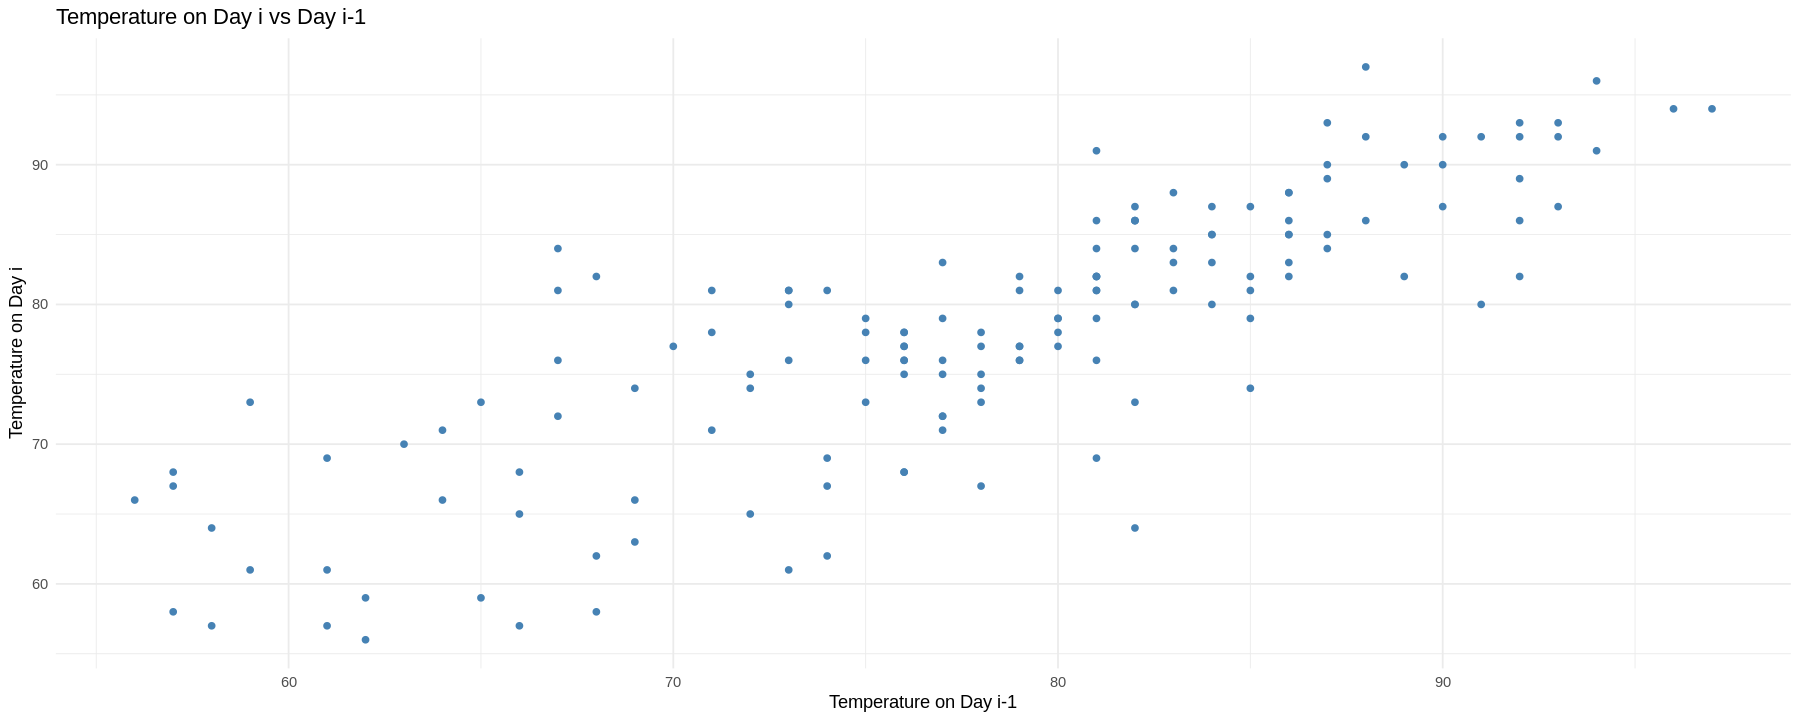

In [86]:
Temp_i   <- airquality$Temp[-1]
Temp_im1 <- airquality$Temp[-length(airquality$Temp)]

ggplot(data.frame(Temp_im1, Temp_i), aes(x = Temp_im1, y = Temp_i)) +
  geom_point(color = "steelblue") +
  labs(
    title = "Temperature on Day i vs Day i-1",
    x = "Temperature on Day i-1",
    y = "Temperature on Day i"
  ) +
  theme_minimal()

Calculate_Correlation(Temp_i, Temp_im1)


###5. We want to expand on this idead and calcualte correlation for shifts 1 to 100 and plot correlation of temperature with previous days.

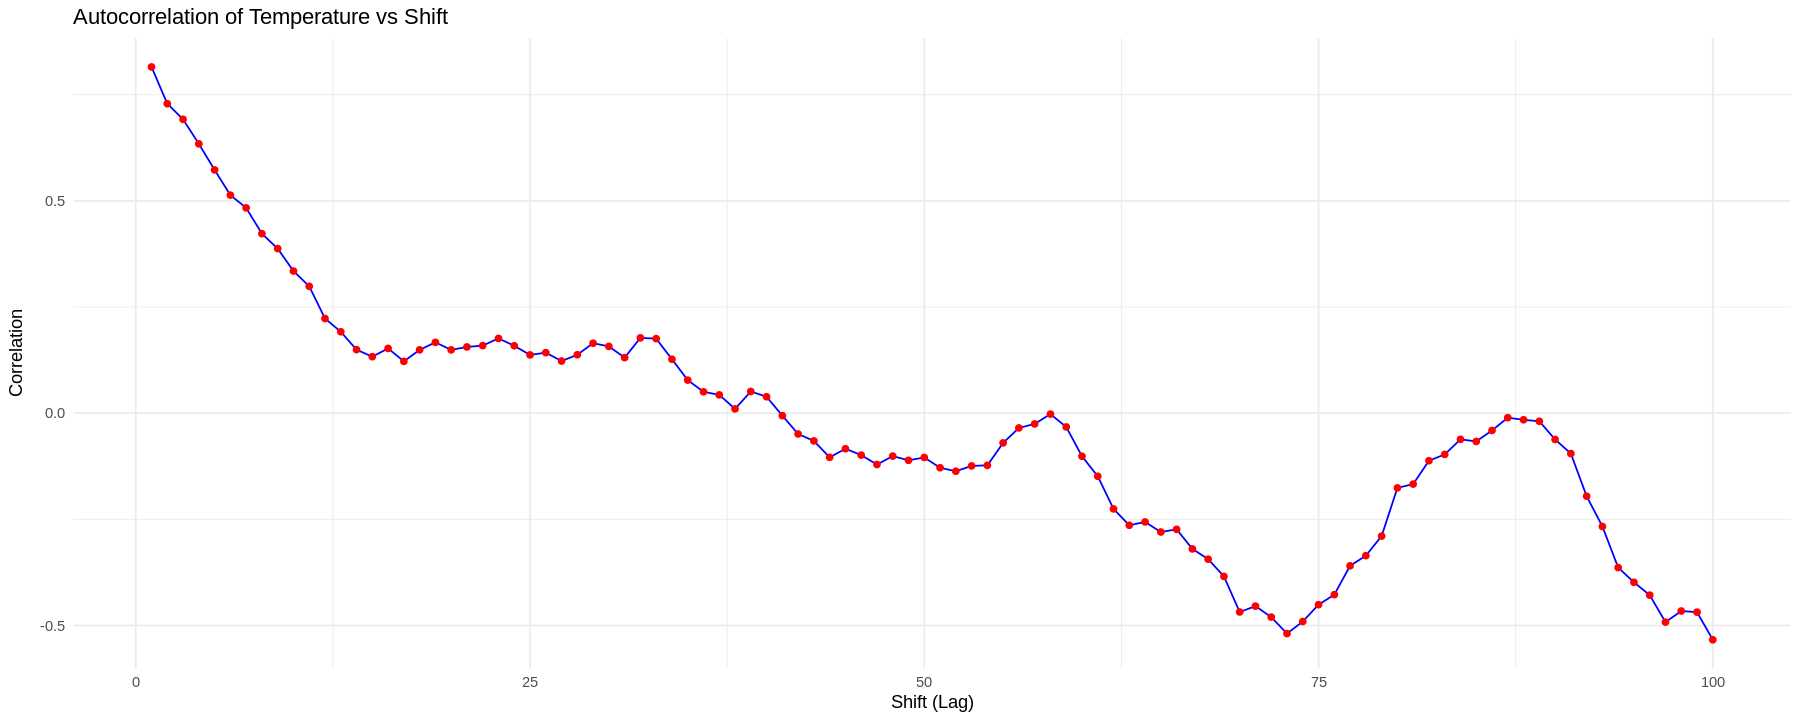

In [87]:
max_shift <- 100
correlations <- numeric(max_shift)

for (s in 1:max_shift) {
  Temp_i <- airquality$Temp[(s + 1):length(airquality$Temp)]
  Temp_is <- airquality$Temp[1:(length(airquality$Temp) - s)]

  correlations[s] <- Calculate_Correlation(Temp_i, Temp_is)
}

ggplot(
  data.frame(Shift = 1:max_shift, Correlation = correlations),
  aes(x = Shift, y = Correlation)
) +
  geom_line(color = "blue") +
  geom_point(color = "red") +
  labs(
    title = "Autocorrelation of Temperature vs Shift",
    x = "Shift (Lag)",
    y = "Correlation"
  ) +
  theme_minimal()


# Question 3
## Conditional Distribution 🤖

For this part we want to locate a robot (WALL-E) in a 10 by 15 grid like maze using it's
sensors.

WALL-E has 4 sensors in its 4 directions that inform it of the presence or absence of a wall in each direction. Each of these 4 sensors has a 10% error. The probability distribution of the result of each sensor is as follows:

$$P(\text{sensor} = 1 | \text{wall} = 1) = 0.9$$
$$P(\text{sensor} = 1 | \text{wall} = 0) = 0.1$$
$$P(\text{sensor} = 0 | \text{wall} = 1) = 0.1$$
$$P(\text{sensor} = 0 | \text{wall} = 0) = 0.9$$

WALL-E is really old and his legs 🦿 are not what they used to be, so even if he chooses to go up, he may go south!!!

given each intended direction, there is a probability of 80% of correctly moving
and 20% moving in the wrong direction (uniformly).
$$P(\text{move} = \text{UP} | \text{intendedDir} = \text{UP}) = 0.8$$
$$P(\text{move} = \text{DOWN} | \text{intendedDir} = \text{UP}) = \frac{0.2}{3}$$
$$P(\text{move} = \text{RIGHT} | \text{intendedDir} = \text{UP}) = \frac{0.2}{3}$$
$$P(\text{move} = \text{LEFT} | \text{intendedDir} = \text{UP}) = \frac{0.2}{3}$$

WALL-E may be old but it has a strong memory 🧠, it stores the history of it's beliefs(the probability of being at each cell each step, more on this later)

WALL-E  wants to find it's location with high accuracy using probabilistic methods and conditional probability to escape from the maze!!! 🌽

To solve this problem, we model it with a set of random variables. Suppose that $X_t$ represents the robot's location after t movements.
Initially the probability of the robot being present in all blocks is equal,
meaning the initial probability for each block (x,y) is:
$$P(X_{0} = (x,y)) = \frac{1}{\text{NUM OF FREE CELLS}}$$

Also, suppose we denote the data read from the sensors at time t by $E_t$ (evidence after t movements 🕵️).



**Common Mistake ✖️**

Random variables $X_{t}$ and $E_{t}$ are vectors!!!

$X_{t}$ shows the location of WALL-E using x,y coordinates for example [3,4].

$E_{t}$ shows the status of WALL-E's sensors for example [0,0,0,1] (only one sensor is on while the others are off)

In our model, $X_{t}$ only depends on $X_{t-1}$ and each $E_t$ also only depends on $X_{t}$ (independent from other random variables).

we can consider a set of random variables:

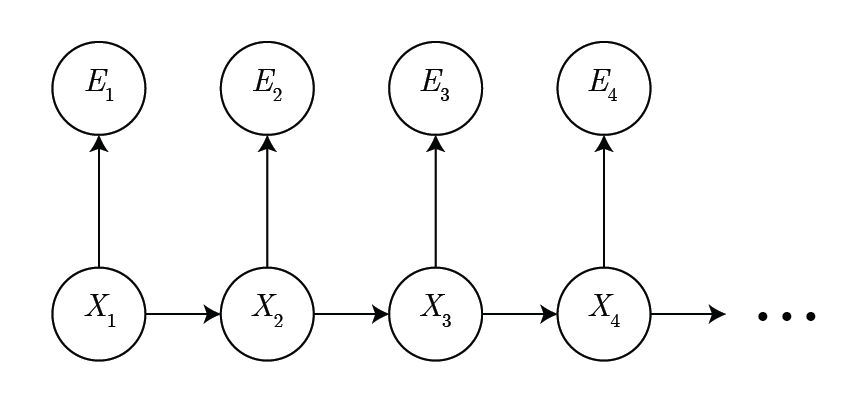


Each arrow indicates the dependence of the variable at the end of the arrow on the variable at the beginning of the arrow.

**What are we looking for? 🔍**

we are looking to estimate $X_t$ from evidences $E_1$ to $E_t$ for each block of the map. So for each step we need to obtain the following probability value:

$$ P(X_{t} | E_1, E_2, ... E_t)$$

This probability can be written as:

$$ { \color{#55cffd} {P(X_t|E_{1:t}) \propto P(X_t, E_{1:t}) \
= \sum_{X_{t-1}} P(X_{t-1}, X_t, E_{1:t}) \
= \sum_{X_{t-1}} P(X_{t-1}, E_{1:t-1}) P(X_t|X_{t-1}) P(E_t|X_t) \
\propto P(E_t|X_t) \sum_{X_{t-1}} P(X_t|X_{t-1}) P(X_{t-1} \mid E_{1:t-1})}}$$

So we will need 3 probabilities:

1. $ P(E_t|X_t) $
2. $ P(X_t|X_{t-1}) $
3. $ P(X_{t-1}, E_{1:t-1}) $

### 0. Theoretical Calculation of Presence Probability**

- Assume we have a $2 \times 3$ grid as shown below.


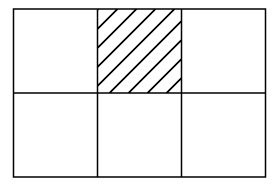

If the robot selects the **DOWN** direction and, after moving, makes the following observation:

$$E_2 = [ \text{UP} = 0, \text{RIGHT} = 0, \text{DOWN} = 1, \text{LEFT} = 1 ]$$

Then, calculate:

$$P(X_2|E_{1:2})$$

(Assume that $P(X_1|E_1)$ is uniformly $0.2$ for all empty cells).

Is the result as expected?

با در نظر گرفتن مدل احتمالاتی حرکت ربات و داده‌های دریافتی از سنسورها، می‌توان مشاهده کرد که توزیع احتمال مکان ربات پس از دریافت شواهد جدید به‌شدت روی یک سلول مشخص متمرکز می‌شود. این تمرکز ناشی از تطابق بسیار قوی قرائت‌های سنسوری با ساختار دیوارهای اطراف آن سلول است.

از آن‌جا که توزیع اولیه مکان ربات به‌صورت یکنواخت در نظر گرفته شده و احتمال حرکت صحیح ربات نسبتاً بالا است، نقش داده‌های سنسورها در به‌روزرسانی باور ربات بسیار پررنگ‌تر از عدم‌قطعیت حرکت می‌باشد. مشاهده‌ی ثبت‌شده تنها با یک موقعیت خاص در محیط سازگار است و سایر موقعیت‌ها به دلیل ناسازگاری با الگوی سنسورها، احتمال بسیار کمتری دریافت می‌کنند.

بنابراین، پس از ترکیب اطلاعات حرکت و مشاهده، مکان محتمل ربات به‌صورت معناداری مشخص می‌شود. این نتیجه کاملاً منطقی و مورد انتظار است، زیرا سنسورها با دقت بالا اطلاعات محیطی قابل اتکایی ارائه می‌دهند و مشاهده‌ی انجام‌شده به‌طور یکتایی ساختار محیط را مشخص می‌کند.

### Basic definitions
This section contains the map, list of movements and constant values.
+ 🔴 **You do not need to change this section.**

+ The function `generate_directions` generates a sequence of moves specified by the strings u, l, d, r and outputs the list of moves.

In [88]:
generate_directions <- function(map, start_pos = c(2, 3), n = 300, valid_ratio = 0.9) {
  directions <- c("u", "d", "l", "r")
  moves <- list(u = c(-1, 0), d = c(1, 0), l = c(0, -1), r = c(0, 1))

  pos <- start_pos
  chosen_dirs <- character(0)
  valid_moves <- 0

  NUM_ROWS <- nrow(map)
  NUM_COLS <- ncol(map)

  while (length(chosen_dirs) < n) {
    dir <- sample(directions, 1)
    new_pos <- pos + moves[[dir]]

    if (new_pos[1] < 1 || new_pos[1] > NUM_ROWS ||
        new_pos[2] < 1 || new_pos[2] > NUM_COLS ||
        map[new_pos[1], new_pos[2]] == 1) {
      if (runif(1) > valid_ratio) {
        chosen_dirs <- c(chosen_dirs, dir)
      }
    } else {
      pos <- new_pos
      chosen_dirs <- c(chosen_dirs, dir)
      valid_moves <- valid_moves + 1
    }
  }

  return(chosen_dirs)
}

In [89]:
map <- matrix(c(
  1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
  1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
  1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1,
  1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1,
  1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1,
  1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1,
  1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1,
  1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1,
  1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1,
  1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
), nrow = 15, ncol = 10) %>% t()

dim = dim(map)

NUM_ROWS = dim[1]
NUM_COLS = dim[2]
SENSOR_ERROR = 0.1
MOVE_ERROR = 0.2
INITIAL_POS = c(2,3)

# List of robot movements Generated by a function. You can change the percentage of moves that are valid (do not hit the wall) and the number of moves.
# The output is a list of 4 letters u, d, l, r.
chosen_dirs <- generate_directions(map, start_pos = INITIAL_POS, n = 300, valid_ratio = 0.9)

actions <- list(
  u = c(y = -1, x = 0),
  d = c(y = 1, x = 0),
  l = c(y = 0, x = -1),
  r = c(y = 0, x = 1)
)

action_names <- names(actions)


###  1. Finding The Evidence!!! 🔍
+ a function that takes WALL-E's current position and the map and returns the values of the top, right, bottom, and left sensors (4 element list).
These are the values of WALL-E's sensors (or evidences of our model).

+ 🔴 **You do not need to change this section.**


In [90]:
sensor <- function(map, current_pos) {

  get_single_reading <- function(target_pos) {

    is_wall_present <- FALSE
    if (map[target_pos[1], target_pos[2]] == 1) {
      is_wall_present <- TRUE
    }
    true_value <- ifelse(is_wall_present, 1, 0)

    random_chance <- runif(1)
    if (random_chance <= (1 - SENSOR_ERROR)) {
      return(true_value)
    }
    else {
      return(1 - true_value)
    }
  }

  pos_up <- current_pos + actions$u
  pos_down <- current_pos + actions$d
  pos_left <- current_pos + actions$l
  pos_right <- current_pos + actions$r

  reading_up <- get_single_reading(pos_up)
  reading_down <- get_single_reading(pos_down)
  reading_left <- get_single_reading(pos_left)
  reading_right <- get_single_reading(pos_right)

  return(list(u = reading_up, r = reading_right, d = reading_down, l = reading_left))
}

### 2. Find WALL-E's Next Position 🔍
+ Write a function that takes WALL-E's current position and it's chosen direction and returns the position after the movement.

In [91]:
move <- function(map, current_pos, chosen_dir) {
  new_pos <- current_pos + actions[[chosen_dir]]

  if (new_pos[1] < 1 || new_pos[1] > nrow(map) ||
      new_pos[2] < 1 || new_pos[2] > ncol(map) ||
      map[new_pos[1], new_pos[2]] == 1) {
    return(current_pos)
  }

  return(new_pos)
}


### 3.  Calculating $ P(E_t|X_t) $ 🧮
+ 3.1. Theoritically calculate the above probability using $E_t = [0,1,0,1]$ and $X_t = [3,4]$ for the map given above.
+ 3.2. Write a function that takes the last evidence ($E_t$) and WALL-E's position ($X_t$) and return the probability $ P(E_t|X_t) $.
+ 3.3. Check your 3.1. answer using 3.2. function

3.1:
برای محاسبه‌ی احتمال مشاهده، وضعیت واقعی دیوارهای اطراف موقعیت ربات با داده‌ی سنسورها مقایسه می‌شود. با توجه به نقشه، در موقعیت (3,4) تنها بخشی از قرائت‌های سنسورها با وضعیت واقعی محیط سازگار هستند و برخی از آن‌ها عدم تطابق دارند. از آن‌جا که دقت سنسورها ۹۰ درصد است، در جهاتی که گزارش سنسور با وضعیت واقعی دیوار مطابقت دارد، احتمال ۰٫۹ و در جهاتی که تطابق وجود ندارد، احتمال ۰٫۱ در نظر گرفته می‌شود. در این حالت، دو سنسور گزارش درست و دو سنسور گزارش نادرست ارائه داده‌اند. بنابراین، احتمال کلی مشاهده برابر با ۰٫۰۷۲۹ به دست می‌آید.

3.2. **$ P(E_t|X_t) $ Function**

In [92]:
cal_observation_prob <- function(map, xt, et) {
  directions <- list(
    u = c(-1, 0),
    r = c(0, 1),
    d = c(1, 0),
    l = c(0, -1)
  )

  probs <- numeric(4)
  i <- 1

  for (dir in names(directions)) {
    neighbor <- xt + directions[[dir]]

    is_wall <- FALSE
    if (neighbor[1] < 1 || neighbor[1] > nrow(map) ||
        neighbor[2] < 1 || neighbor[2] > ncol(map) ||
        map[neighbor[1], neighbor[2]] == 1) {
      is_wall <- TRUE
    }

    if (is_wall) {
      probs[i] <- ifelse(et[i] == 1, 0.9, 0.1)
    } else {
      probs[i] <- ifelse(et[i] == 0, 0.9, 0.1)
    }

    i <- i + 1
  }

  prod(probs)
}


3.3. **Comparing the results**

In [93]:
cal_observation_prob(map, xt = c(3, 4), et = c(0, 1, 0, 1))


[1] 0.0729

### 4. Calculating $ P(X_t|X_{t-1}) $ 🧮
+ Write a function that takes $X_t$, $X_{t-1}$, and the direction chosen by the WALL-E and outputs the probability that WALL-E will go from $X_{t-1}$ to $X_t$ given the input direction.

+ For example, `f((3,4), (3,5) , 'u')` is equal to the probability that WALL-E will go from house (3,5) to (3,4) while choosing the up direction.

+ Note: If $X_{t-1}$ were a wall, we would return 0.

+ Note: If $X_{t-1}$ were not a neighbor of $X_t$ or $X_t$ itself, it is clearly impossible for the robot to go from $X_{t-1}$ to $X_t$. So we would return 0.

+ Note: If $X_t$ were a wall, we would return 0.

In [94]:
cal_move_prob <- function(map, xt, xt_minus_1, chosen_dir) {

  dir_map <- list(
    u = c(-1, 0),
    d = c(1, 0),
    l = c(0, -1),
    r = c(0, 1)
  )

  if (!(chosen_dir %in% names(dir_map))) return(0)

  if (map[xt_minus_1[1], xt_minus_1[2]] == 1) return(0)
  if (map[xt[1], xt[2]] == 1) return(0)

  diff <- xt - xt_minus_1

   if (all(diff == dir_map[[chosen_dir]])) {
    return(0.8)
  }

   possible_moves <- c(dir_map, list(c(0,0)))

  if (any(sapply(possible_moves, function(m) all(diff == m)))) {
    return(0.2 / 3)
  }

  return(0)
}


In [95]:
cal_move_prob(map, c(3,2), c(2,2), "d")


[1] 0.8

### 5. Main program loop 🔁

+ Write the main loop using the model's formula provided to calculate $P(X_t| E_{1:t})$
+ Don't forget to normalize !! you can use the normalize function below to normalize the belief.

Complete the `model` function so that it returns a binary list of the model's beliefs and the robot's actual positions by taking the map and the chosen directions of the robot:

`return (list(beliefs = beliefs, real_pos = real_pos))`

#### Initializing
Initializing the belief list and the WALL-E's actual position
+ Note: The `beliefs` is a list to store WALL-E's belief about its location at each time step. Each element in this list will be a matrix representing the probability distribution of the robot being in each cell of the grid (belief). Initially, we add a uniform distribution to it.

❗ Beliefs is used to simulate our model and real postions is used to simulate real tracking of WALL-E. we can find our model's perfomance by comparing
beliefs and real positions.

In [96]:
normalize <- function(m) {
  total_sum <- sum(m)
  normalized_m <- m / total_sum
  return(normalized_m)
}

In [97]:
model <- function(map, chosen_dirs) {

  current_pos <- INITIAL_POS

  real_pos = list()
  beliefs <- list()

  initial_probs <- function(map) {
    num_zeros <- sum(map == 0)
    if (num_zeros == 0) {
      return(matrix(0, nrow = nrow(map), ncol = ncol(map)))
    }
    replacement_value <- 1 / num_zeros
    output_mat <- ifelse(map == 0, replacement_value, 0)
    return(output_mat)
  }

  beliefs <- append(beliefs, list(initial_probs(map)))
  real_pos <- append(real_pos, list(INITIAL_POS))

  for (t in 1:length(chosen_dirs)) {

  chosen_dir <- chosen_dirs[t]

  current_pos <- move(map, current_pos, chosen_dir)
  real_pos <- append(real_pos, list(current_pos))

  et <- sensor(map, current_pos)

  prev_belief <- beliefs[[t]]
  new_belief <- matrix(0, nrow = nrow(map), ncol = ncol(map))

  for (i in 1:nrow(map)) {
    for (j in 1:ncol(map)) {

      if (map[i, j] == 1) next

      obs_prob <- cal_observation_prob(map, xt = c(i, j), et = et)

      move_sum <- 0
      for (x in 1:nrow(map)) {
        for (y in 1:ncol(map)) {

          if (map[x, y] == 1) next

          move_prob <- cal_move_prob(
            map,
            xt = c(i, j),
            xt_minus_1 = c(x, y),
            chosen_dir = chosen_dir
          )

          move_sum <- move_sum + move_prob * prev_belief[x, y]
        }
      }

      new_belief[i, j] <- obs_prob * move_sum
    }
  }

  new_belief <- normalize(new_belief)
  beliefs <- append(beliefs, list(new_belief))
}


  return (list(beliefs = beliefs, real_pos = real_pos))
}

In [98]:
result <- model(map, chosen_dirs)
beliefs <- result$beliefs
real_pos = result$real_pos

In [99]:
beliefs[[length(beliefs)]]
real_pos[[length(real_pos)]]


0,0.000000e+00,0.0000000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0
0,1.173214e-05,0.0000103424,5.534199e-13,3.292049e-14,1.053598e-13,7.157982e-19,0.000000e+00,4.238912e-24,3.877309e-24,1.194214e-28,1.152736e-31,1.135000e-31,7.624262e-34,0
0,2.193705e-02,0.0000000000,0.000000e+00,1.180585e-10,0.000000e+00,2.105100e-15,0.000000e+00,3.806272e-21,0.000000e+00,0.000000e+00,0.000000e+00,9.354386e-30,8.265095e-29,0
0,1.600792e-03,0.0001453298,8.126482e-11,8.848302e-09,0.000000e+00,3.413886e-16,2.567584e-17,1.413064e-21,1.031618e-25,1.170743e-26,0.000000e+00,9.926720e-28,0.000000e+00,0
0,1.504447e-01,0.0000000000,1.169689e-07,0.000000e+00,0.000000e+00,2.576079e-14,0.000000e+00,0.000000e+00,0.000000e+00,1.054573e-25,1.167648e-26,1.353207e-30,1.431178e-33,0
0,2.413465e-02,0.0000000000,8.541393e-08,7.944570e-11,1.931362e-15,1.152446e-15,0.000000e+00,9.665751e-25,7.134848e-25,1.355007e-24,0.000000e+00,0.000000e+00,1.422823e-32,0
0,1.020819e-01,0.0000000000,0.000000e+00,0.000000e+00,0.000000e+00,3.497651e-16,0.000000e+00,7.147051e-22,0.000000e+00,9.805243e-26,1.035744e-26,2.196908e-31,1.524984e-32,0
0,1.810357e-03,0.0000797599,1.012191e-09,1.347474e-13,1.589093e-16,8.881178e-17,3.124492e-21,2.897133e-23,0.000000e+00,1.007637e-23,0.000000e+00,0.000000e+00,9.762390e-33,0
0,6.977432e-01,0.0000000000,0.000000e+00,1.389813e-12,0.000000e+00,0.000000e+00,0.000000e+00,1.058613e-23,1.601438e-26,1.126329e-26,9.649127e-30,1.379216e-34,1.226654e-32,0
0,0.000000e+00,0.0000000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0


y x 
6 2

### 6. Visualization 🎨

The following function is used to draw the Maze Heatmap.
+ 🔴 **You do not need to change this section.**

In [100]:
plot_belief_map <- function(map, belief, current_pos) {
  rows <- nrow(map)
  cols <- ncol(map)
  max_idx <- which.max(belief)
  max_belief_pos <- arrayInd(max_idx, .dim = c(rows, cols))
  plot(NA, xlim = c(0, cols), ylim = c(0, rows), type = "n",
       xlab = "", ylab = "", main = "Robot Belief State",
       xaxs = "i", yaxs = "i", xaxt = 'n', yaxt = 'n', asp = 1)
  max_b <- max(belief)
  norm_belief <- if (max_b > 0) belief / max_b else belief
  col_palette <- colorRampPalette(c("#F7FBFF", "#6BAED6", "#08306B"))(101)
  for (r in 1:rows) {
    for (c in 1:cols) {
      xleft <- c - 1
      ybottom <- rows - r
      xright <- c
      ytop <- rows - r + 1

      if (map[r, c] == 1) {
        rect(xleft, ybottom, xright, ytop, col = "grey20", border = "grey50")
      } else {
        color_idx <- floor(norm_belief[r, c] * 100) + 1
        rect(xleft, ybottom, xright, ytop, col = col_palette[color_idx], border = "grey50")
      }
    }
  }
  rect(max_belief_pos[2] - 1, rows - max_belief_pos[1],
       max_belief_pos[2], rows - max_belief_pos[1] + 1,
       border = "#00FFFF", lwd = 4)
  text(x = current_pos[2] - 0.5, y = rows - current_pos[1] + 0.5,
       labels = "X", col = "red", font = 2, cex = 2)
}

### 7. Results 🚀
Using lists `beliefs` and `real_pos`, we'll draw the maze at each step.
+ 🔴 **You do not need to change this section.**

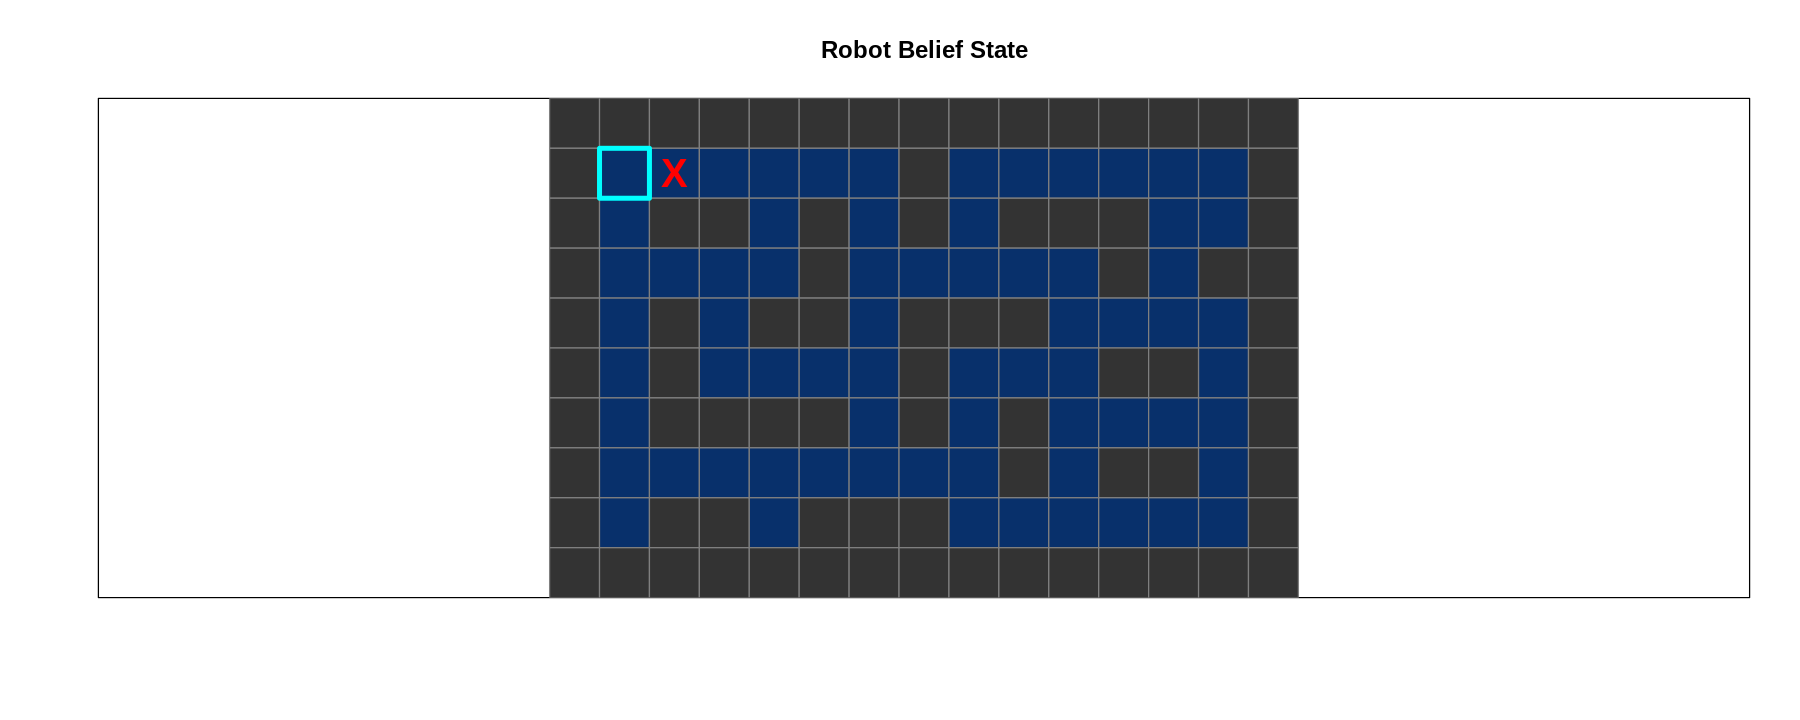

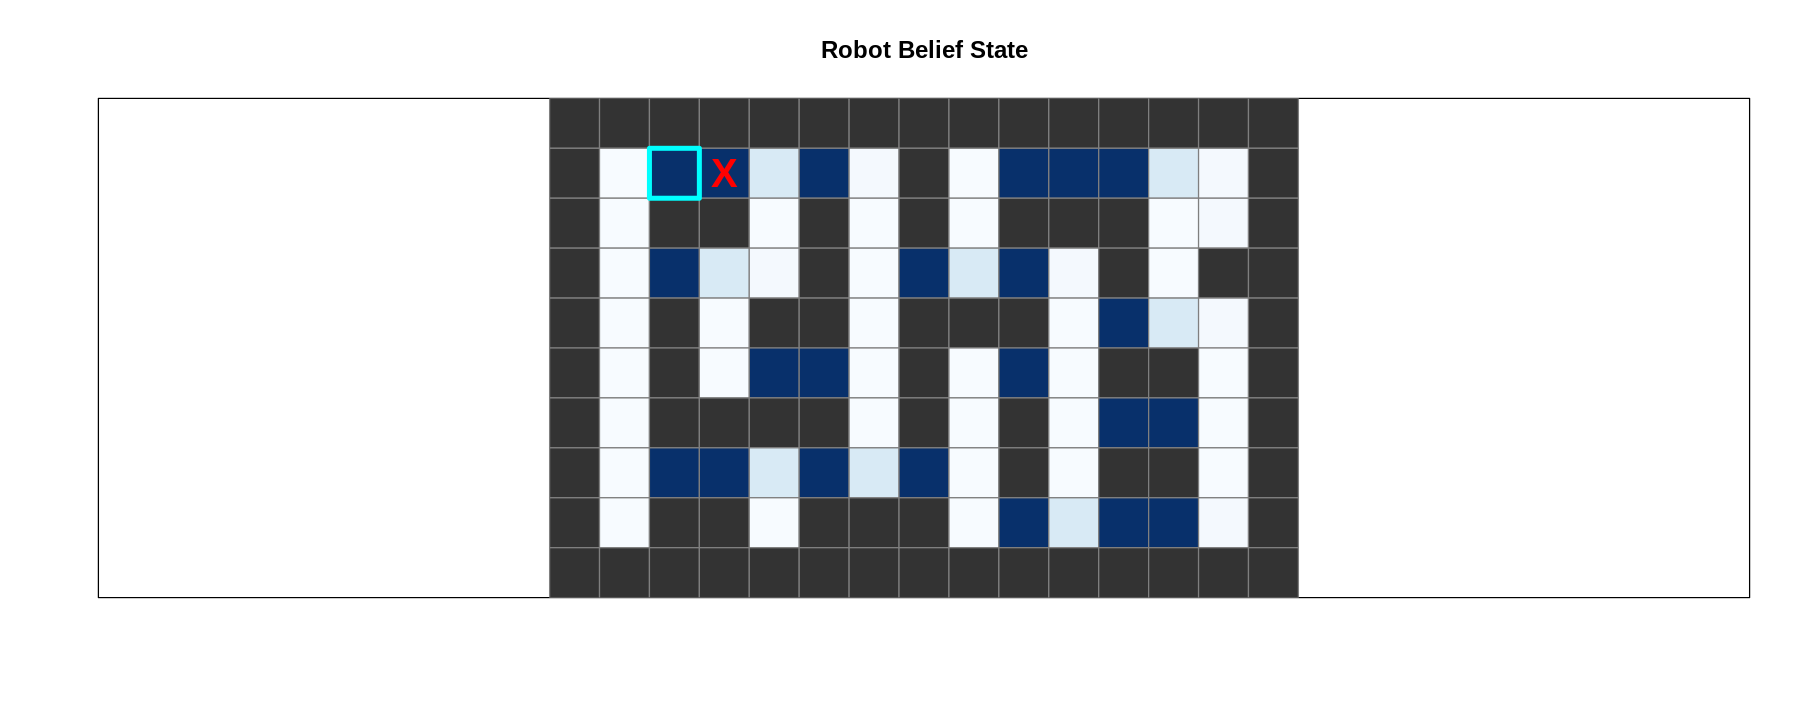

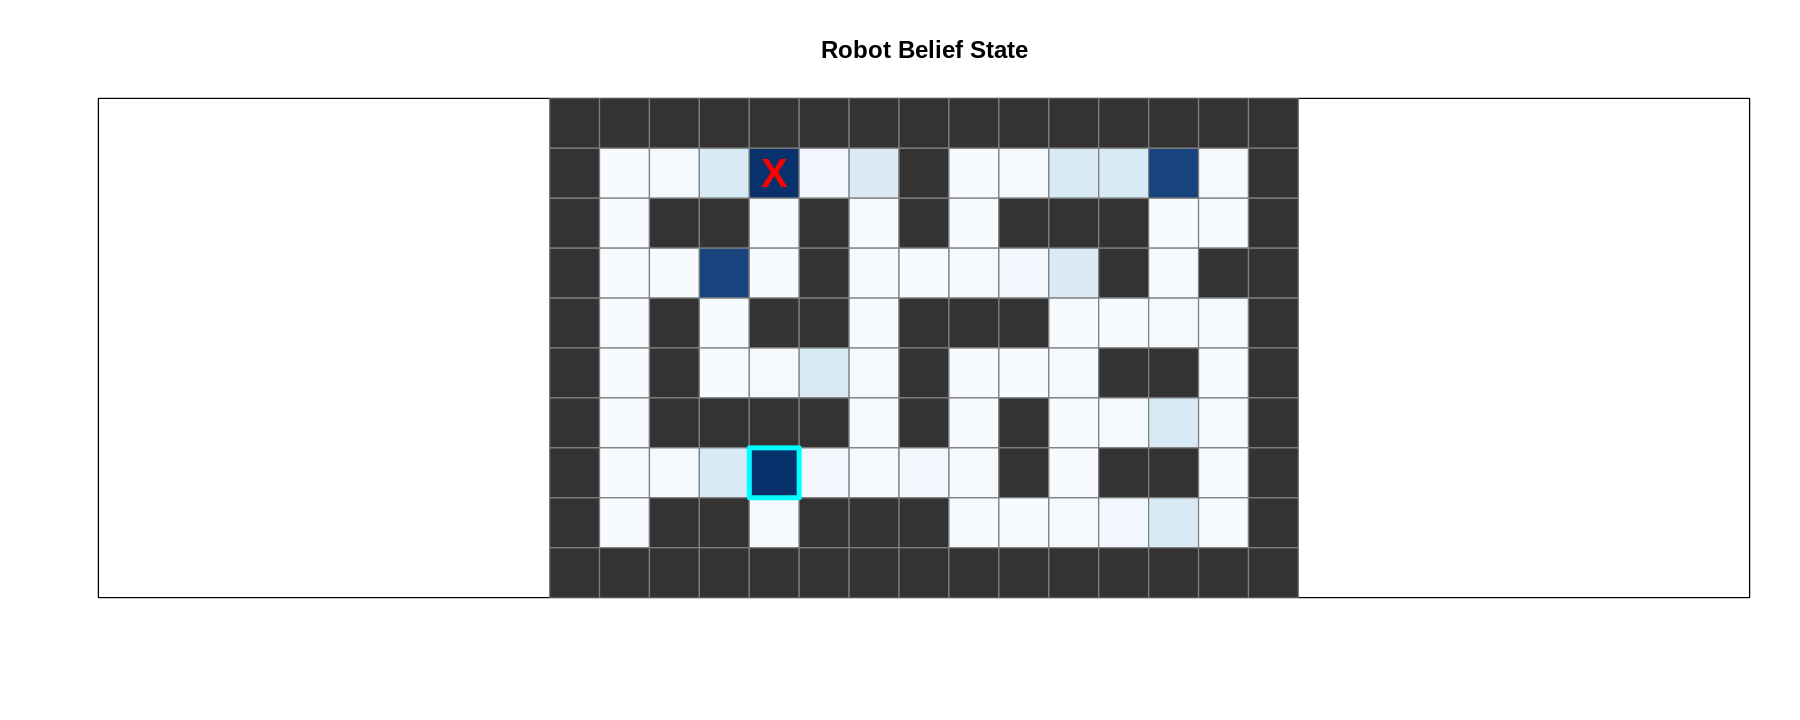

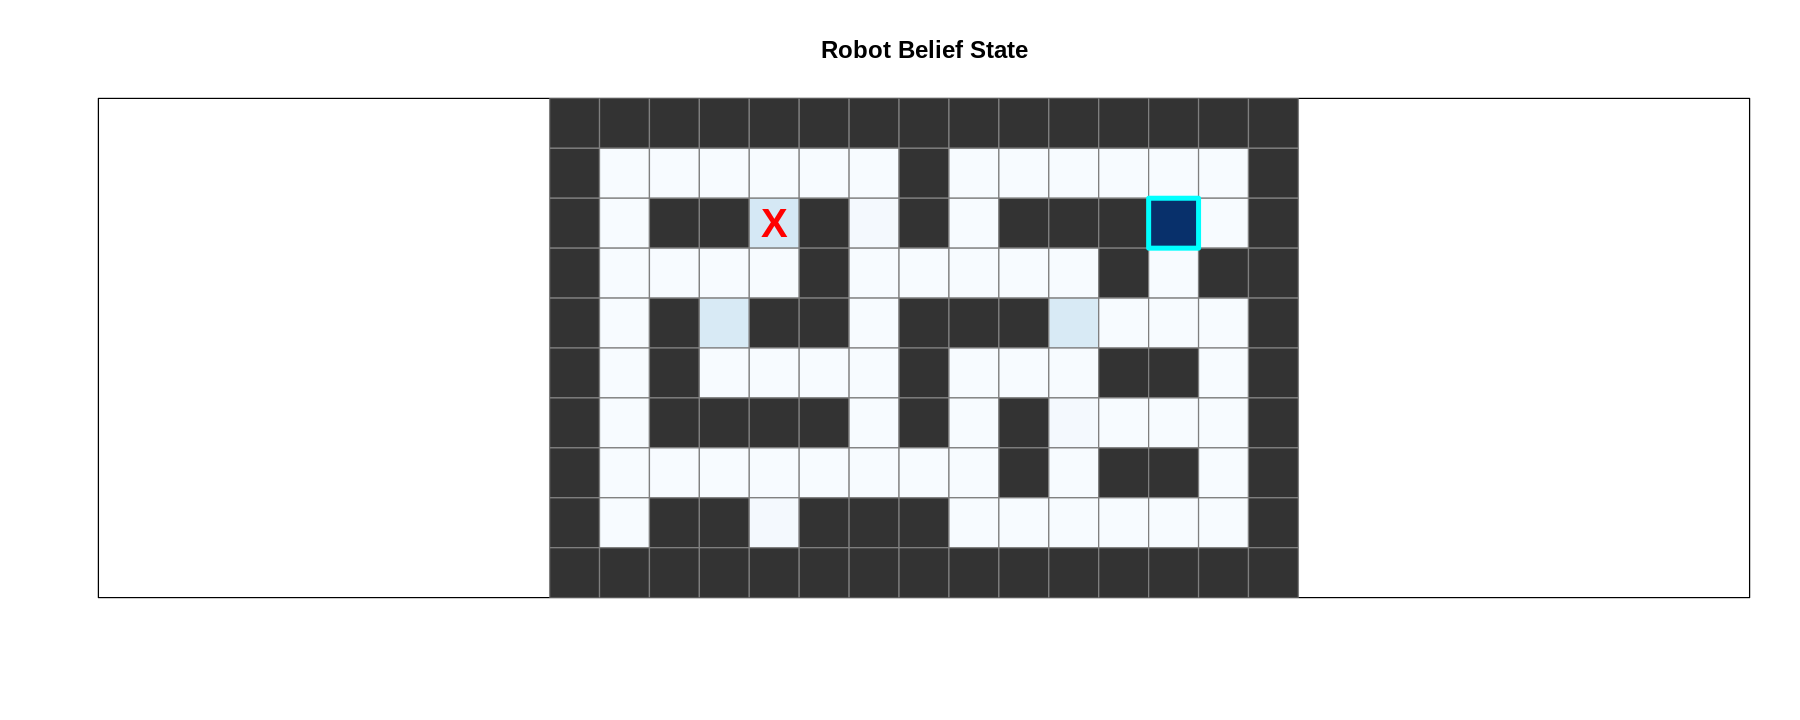

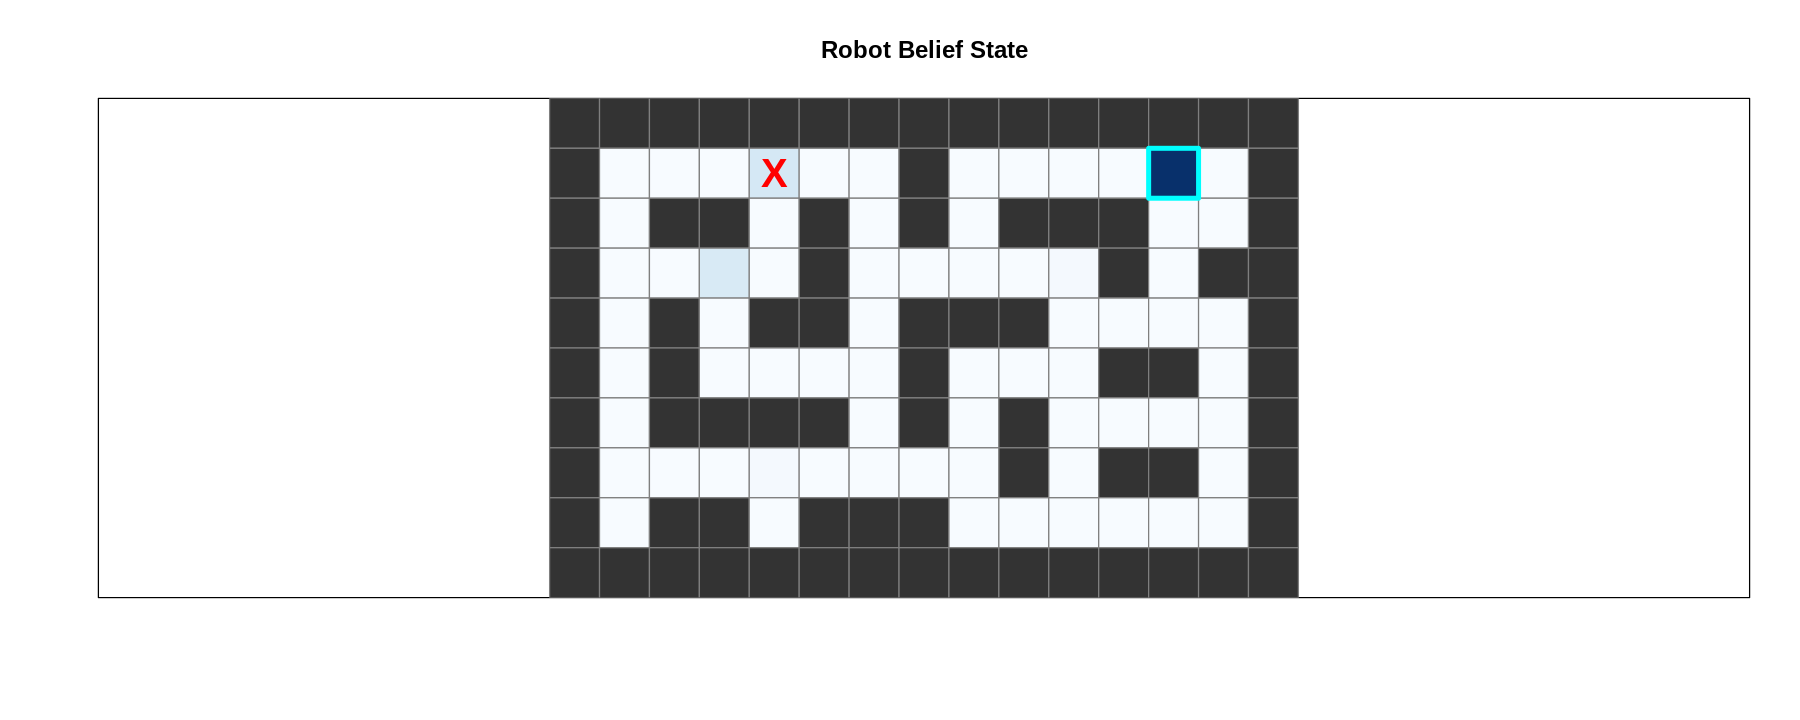

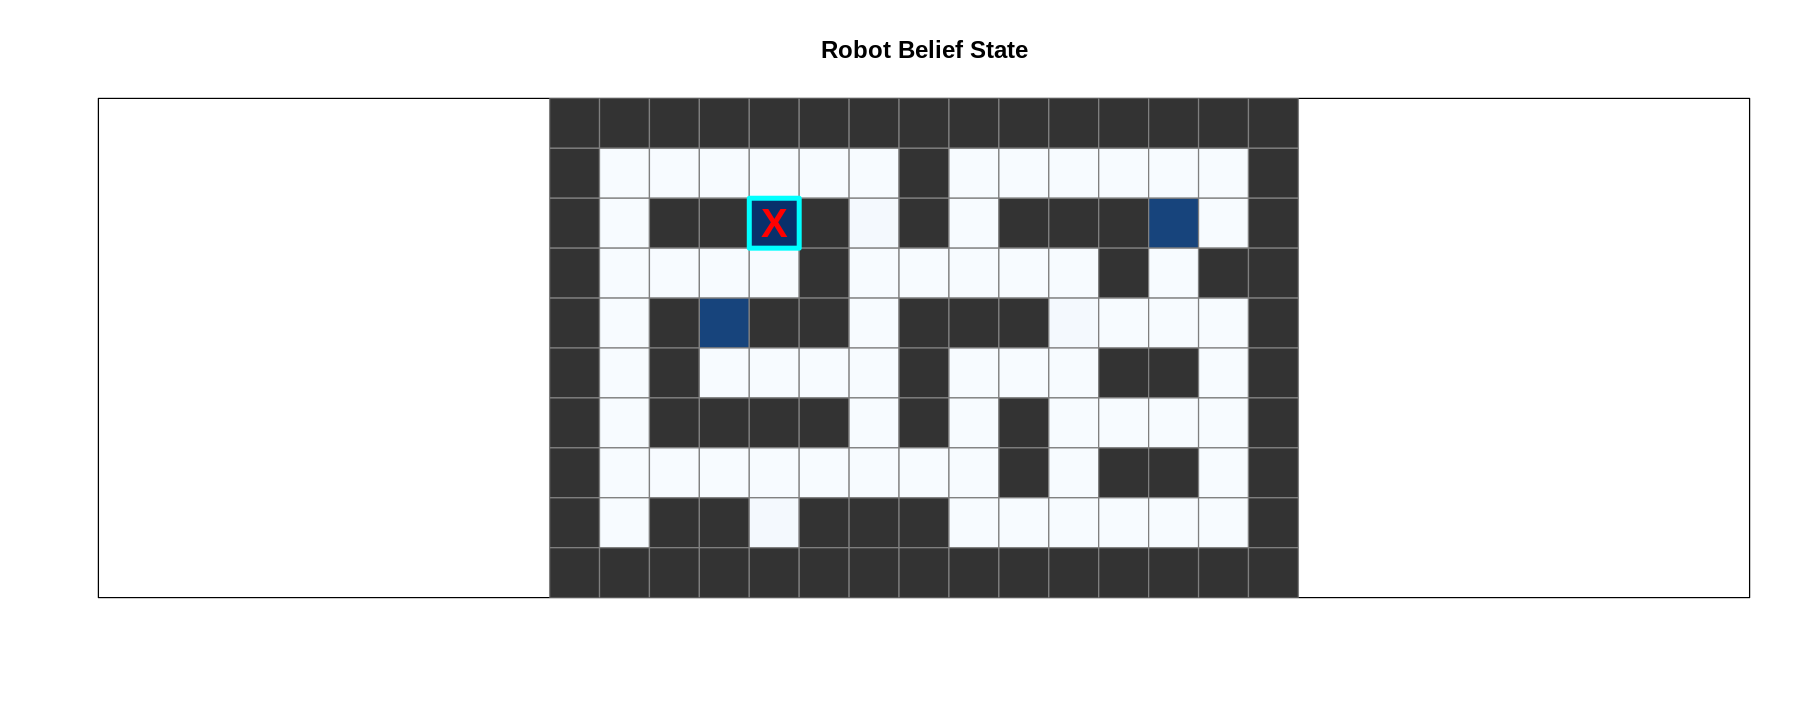

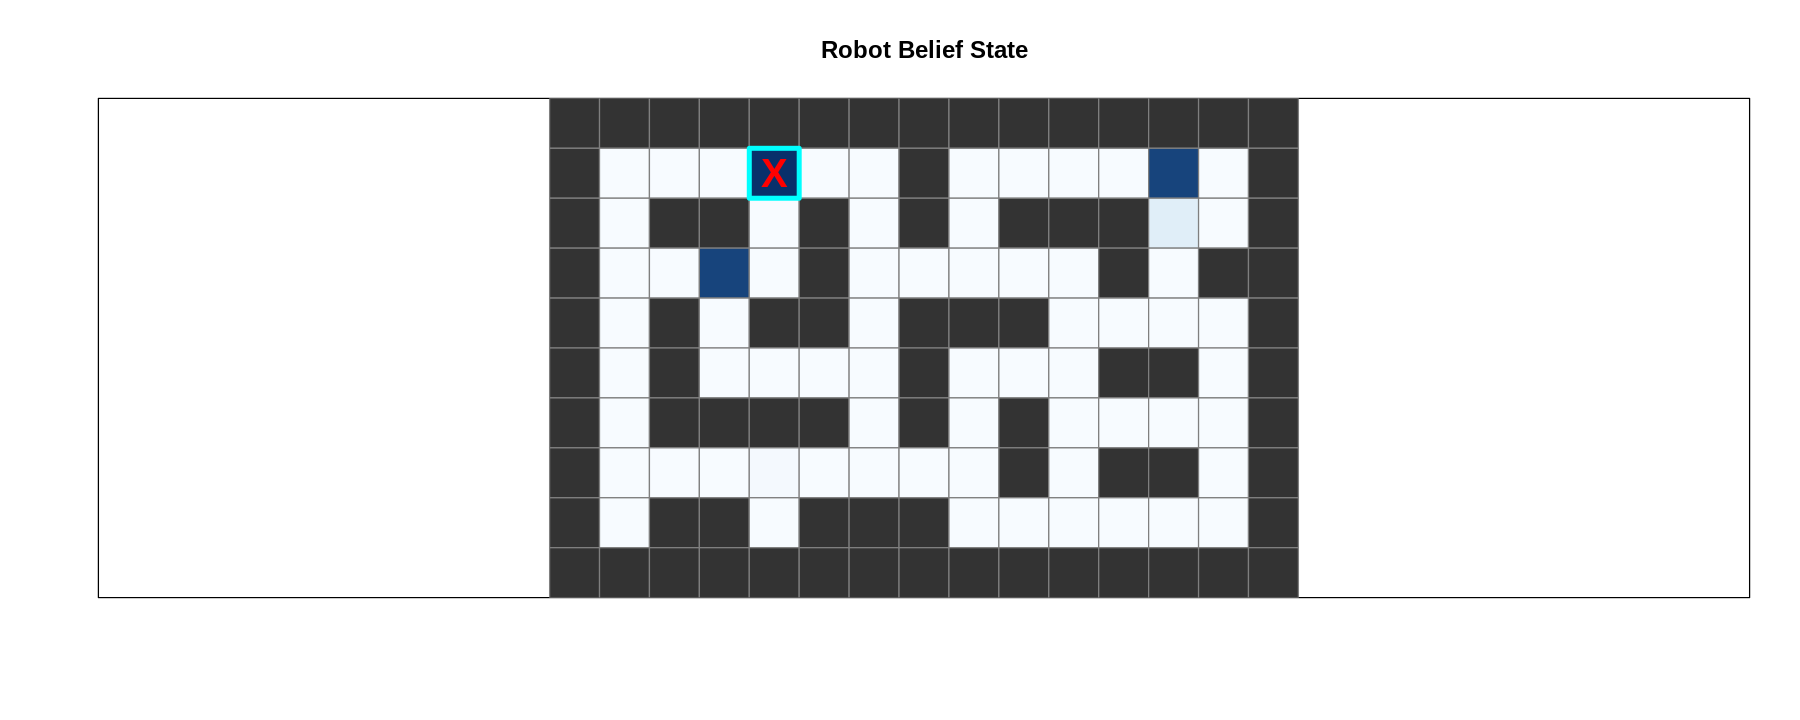

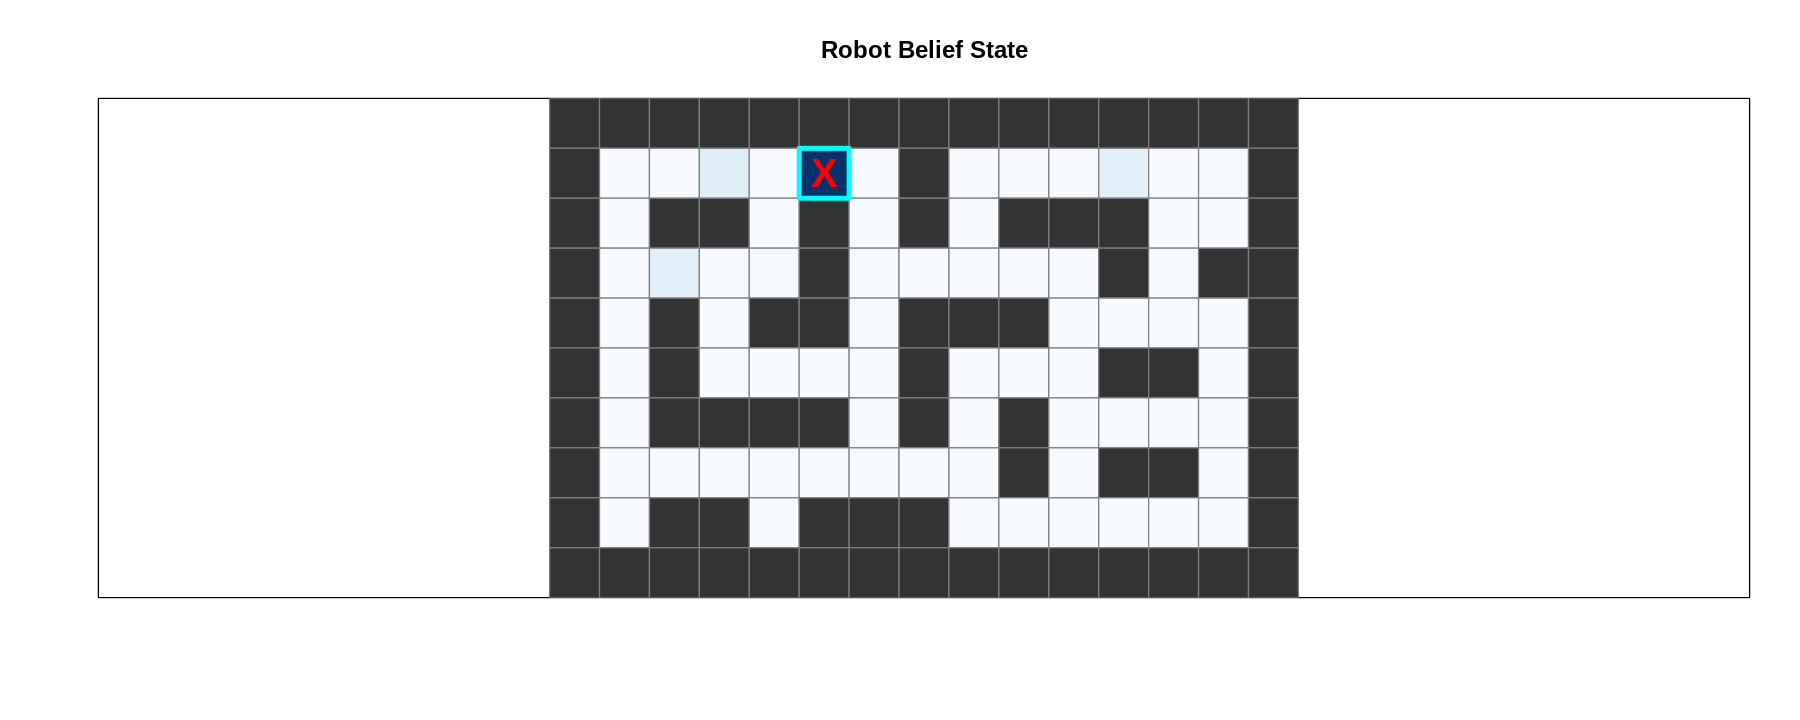

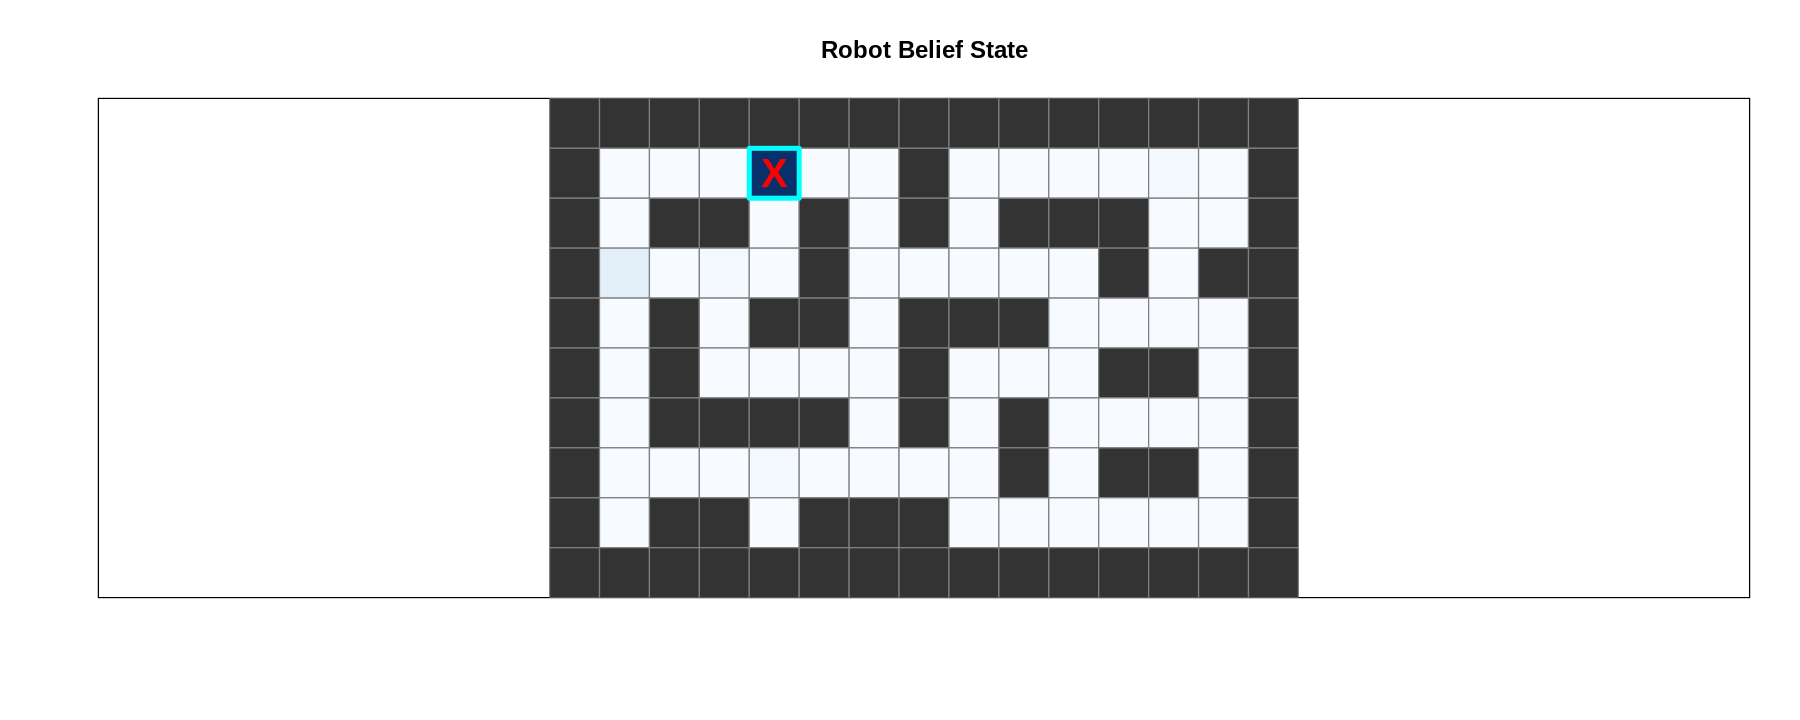

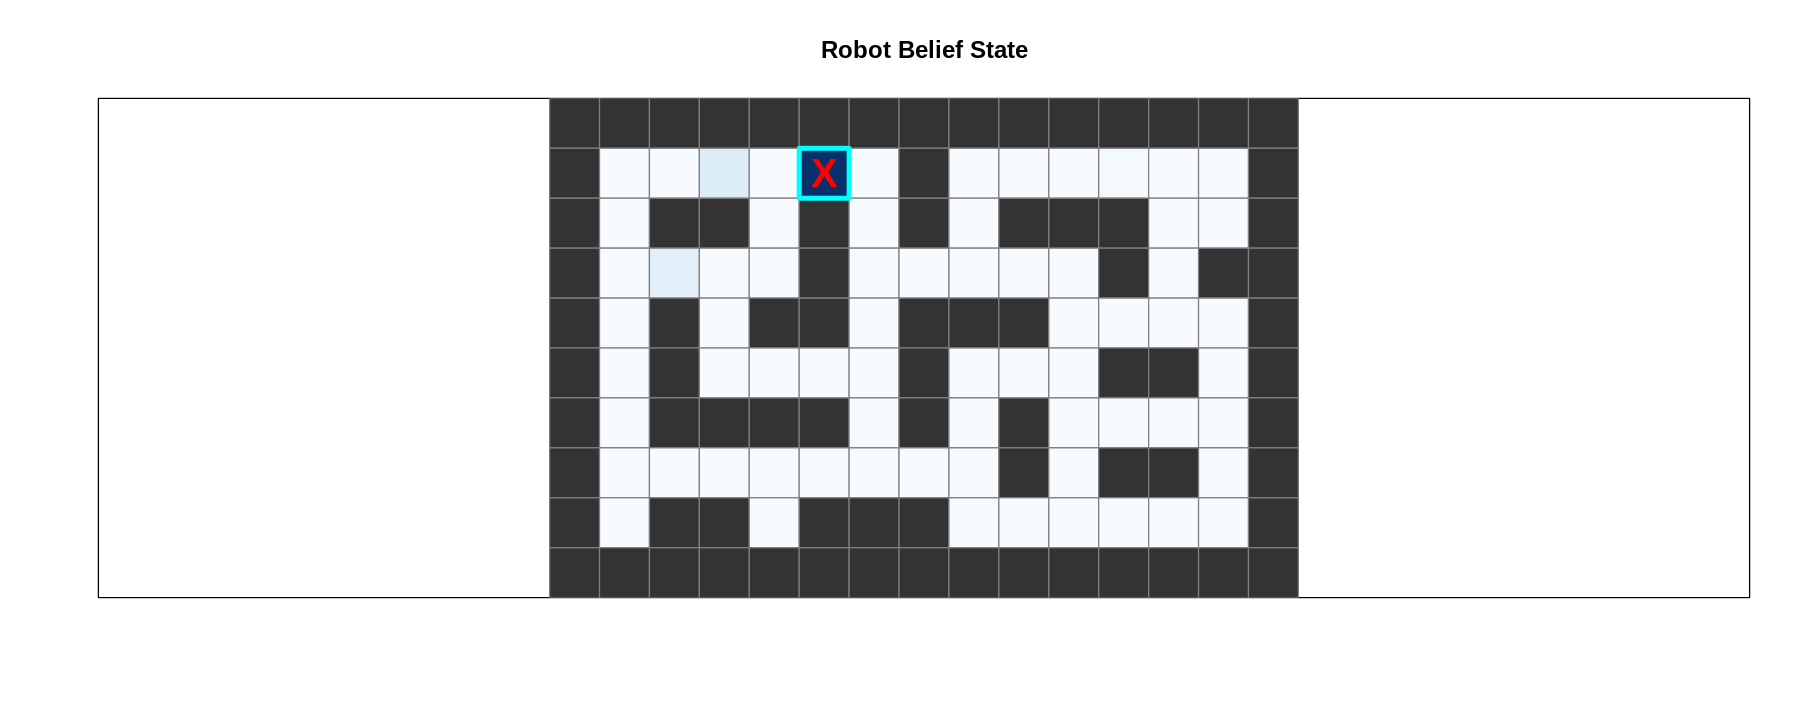

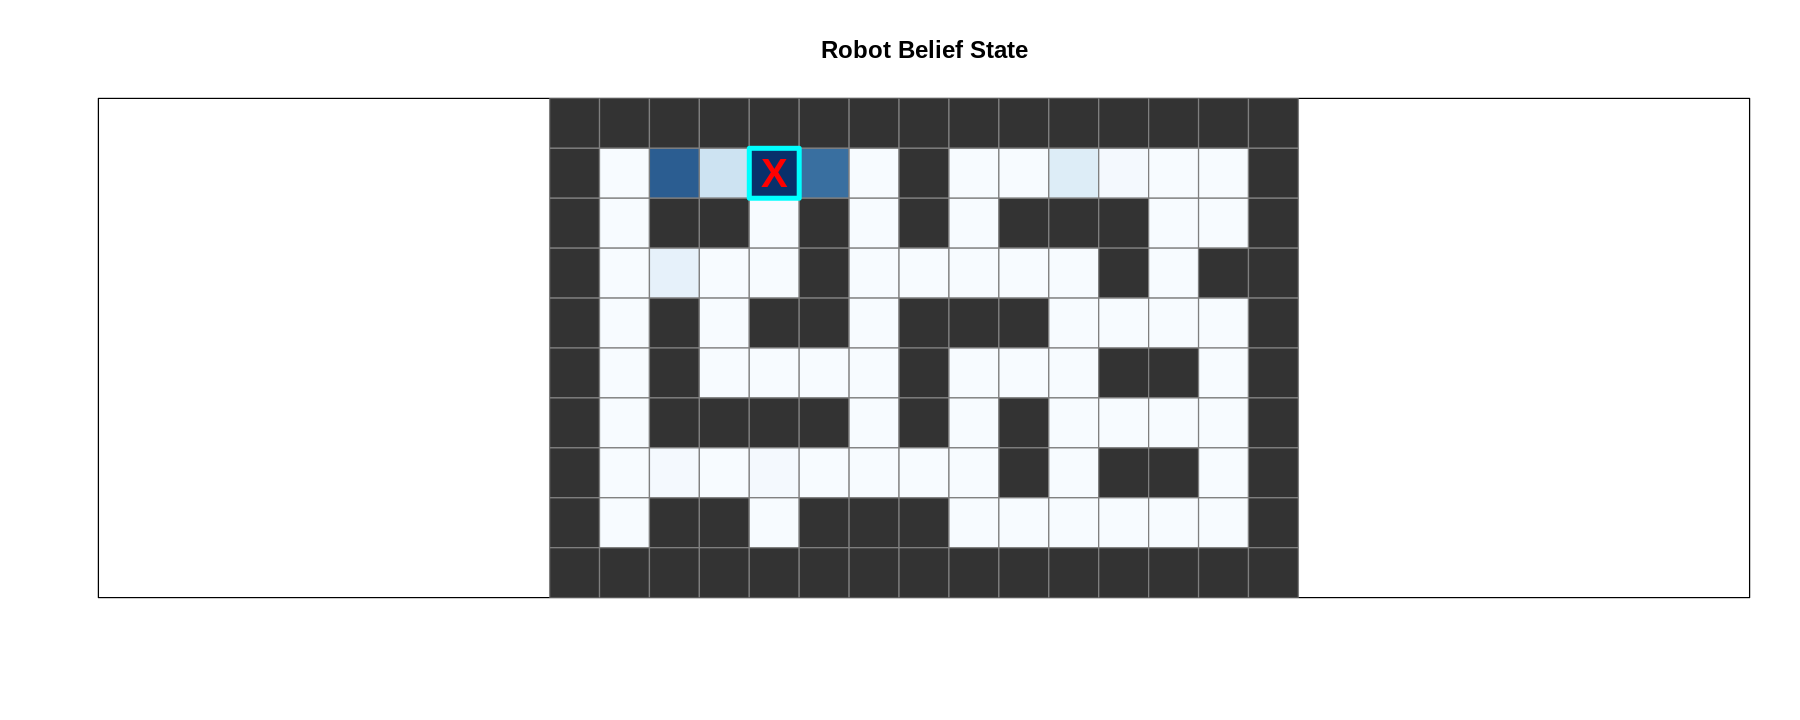

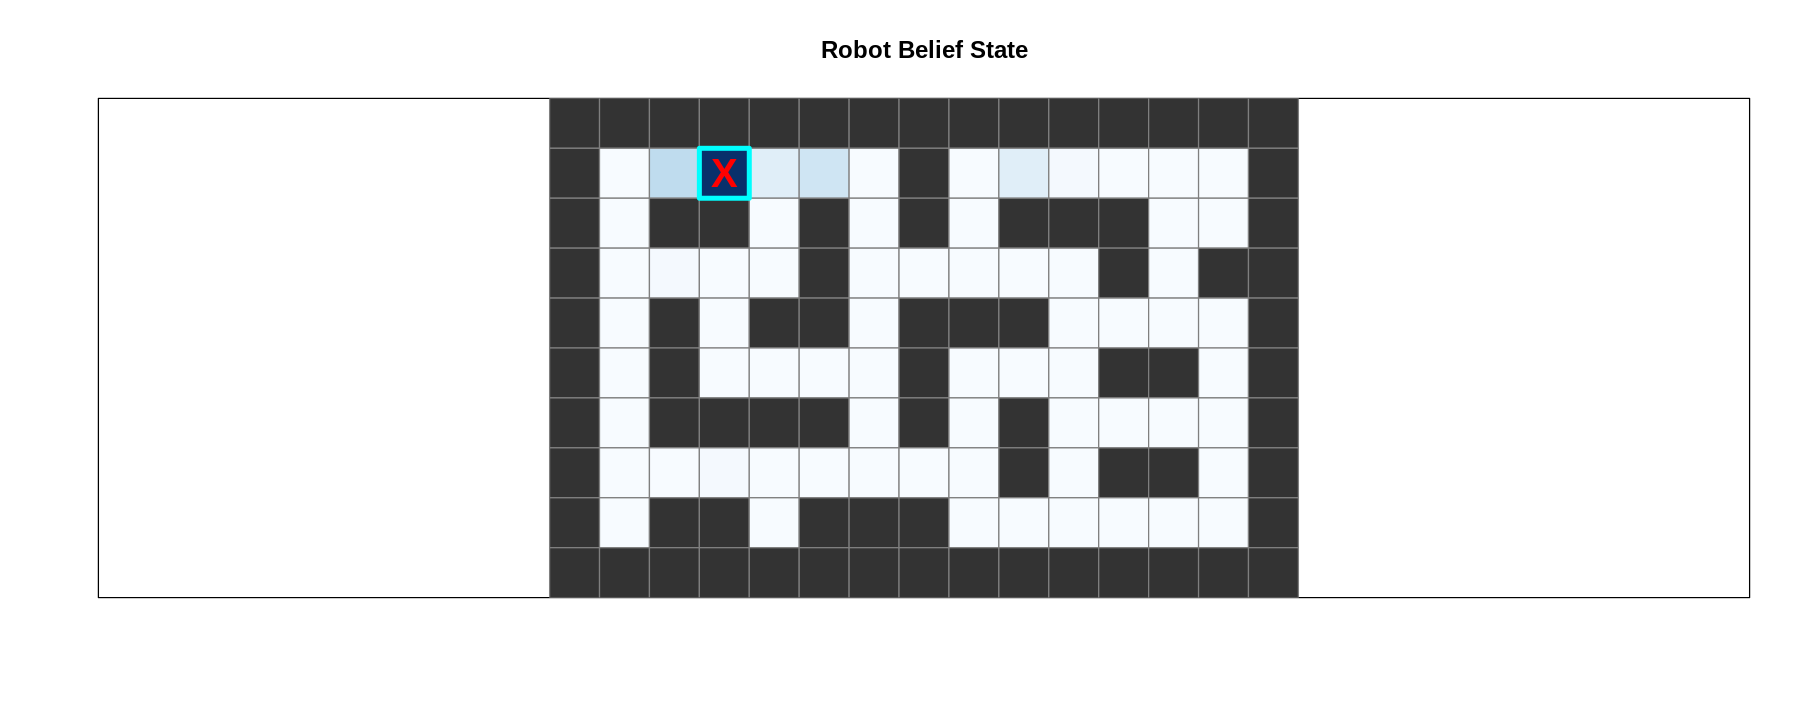

In [101]:
for(i in 1:12) {
  plot_belief_map(map, beliefs[[i]], real_pos[[i]])
}

### 8. Evaluate the results 📈
Pass the output of your model to the following functions. Function `plot_belief_maxima` plots our maximum likelihood belief versus state. Function `plot_belief_accuracy` prints the number of correct predictions in each group of 5 along with the overall accuracy.

In [102]:
plot_belief_maxima <- function(beliefs) {
  if (!is.list(beliefs) || !all(sapply(beliefs, is.matrix))) {
    stop("Input must be a list of matrices.")
  }

    max_values <- sapply(beliefs, max)

  df <- data.frame(
    Index = seq_along(max_values),
    MaxValue = max_values
  )

  return(
    ggplot(df, aes(x = Index, y = MaxValue)) +
    geom_line(color = "blue", linewidth = 1) +
    geom_point(color = "red", size = 3) +
    labs(
      title = "Maximum Value of Each Belief Matrix",
      x = "Matrix Index",
      y = "Maximum Value"
    ) +
    theme_minimal()
  )
}


In [103]:
plot_belief_accuracy <- function(beliefs, real_pos) {
  if (length(beliefs) != length(real_pos)) {
    stop("beliefs and real_pos must have the same length.")
  }

  predicted_pos <- lapply(beliefs, function(b) {
    idx <- which(b == max(b), arr.ind = TRUE)
    return(idx[1, ])
  })

  correct <- mapply(function(p, r) all(p == r), predicted_pos, real_pos)

  n <- length(correct)
  group_indices <- ceiling(seq_len(n) / 5)
  correct_counts <- tapply(correct, group_indices, sum)

  df <- data.frame(
    Group = factor(seq_along(correct_counts)),
    Correct = as.numeric(correct_counts)
  )

  overall_acc <- mean(correct)
  cat(sprintf("Overall accuracy: %.2f%%\n", 100 * overall_acc))

  return(
    ggplot(df, aes(x = Group, y = Correct)) +
    geom_col(fill = "steelblue") +
    labs(
      title = "Correct Predictions per 5 Belief Blocks",
      x = "Group of 5 Beliefs",
      y = "Number of Correct Predictions"
    ) +
    theme_minimal()
  )

}



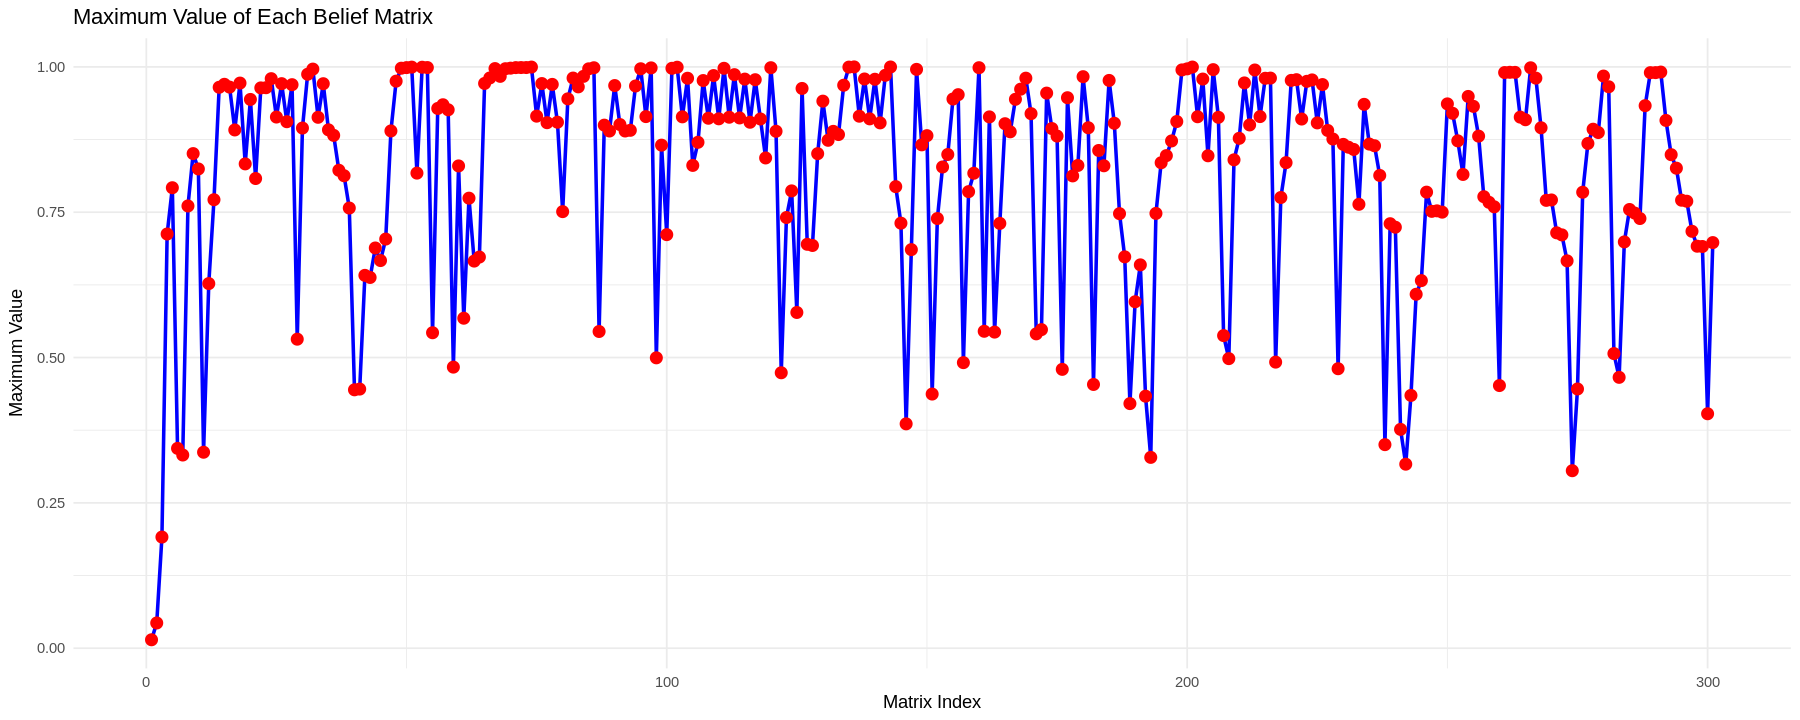

In [104]:
plot_belief_maxima(beliefs)

Overall accuracy: 88.04%


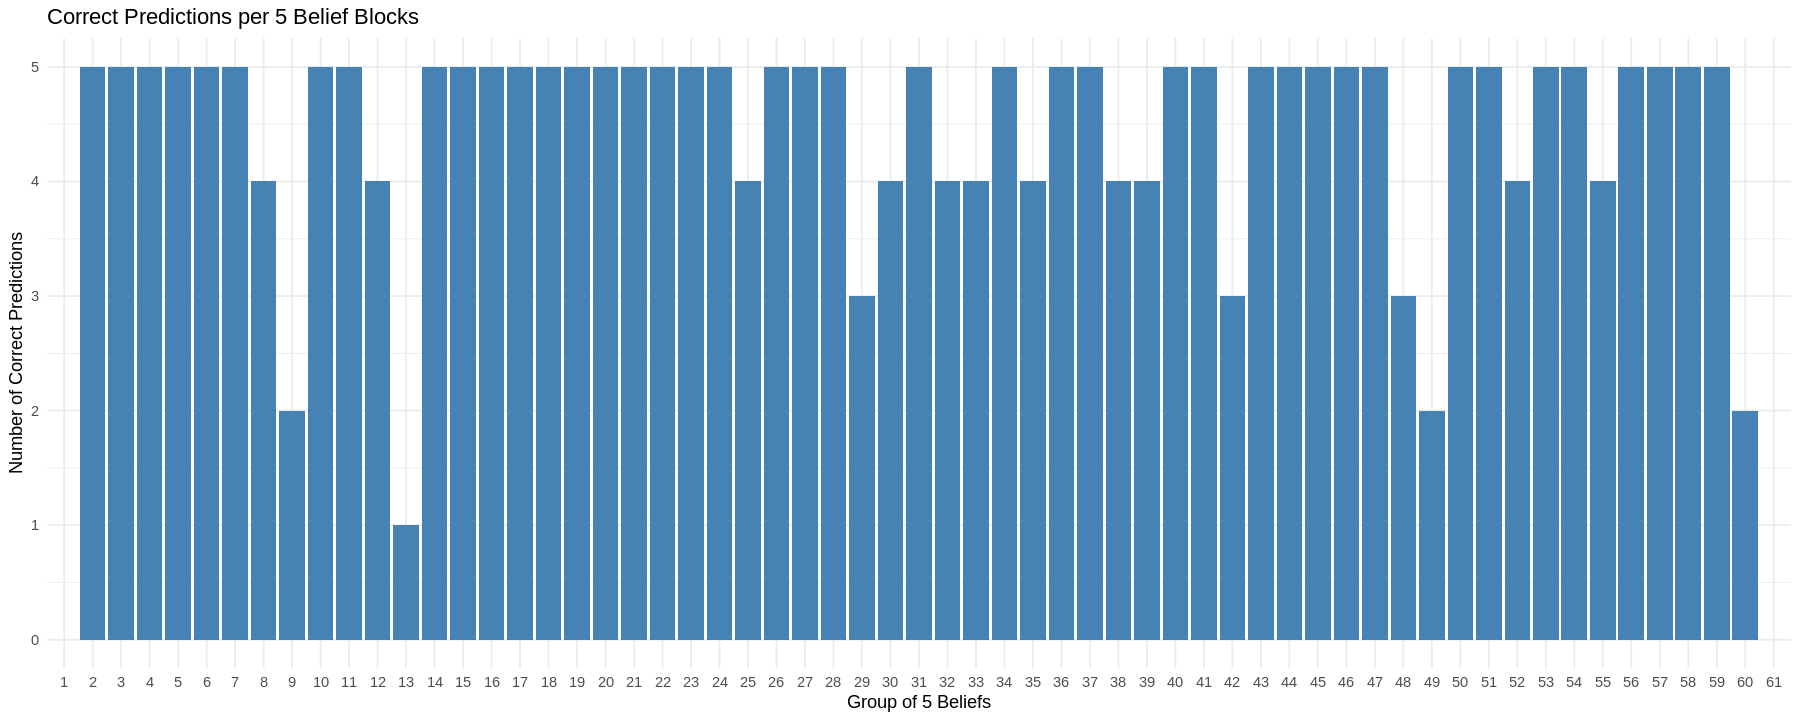

In [105]:
plot_belief_accuracy(beliefs, real_pos)

8.1. Change the model error percentage according to the table below and compare the graphs for 300 moves.
+ At each step, change the `SENSOR_ERROR` and `MOVE_ERROR` values ​​and call the `model` function again and plot the model output with given functions.

| Sensor error | Movement Error |
| ------------ | -------------- |
| 0.01         | 0.01           |
| 0.05         | 0.05           |
| 0.6          | 0.6            |
| 0.6          | 0.001          |
| 0.001        | 0.6            |

+ **Note:** Don't use `for` and plot each graph in a **separate cell**.

8.2. Finally, analyze the results and check the reason for the behavior of each chart. Also, compare the importance of sensor error and movement error according to the results.

Overall accuracy: 97.67%


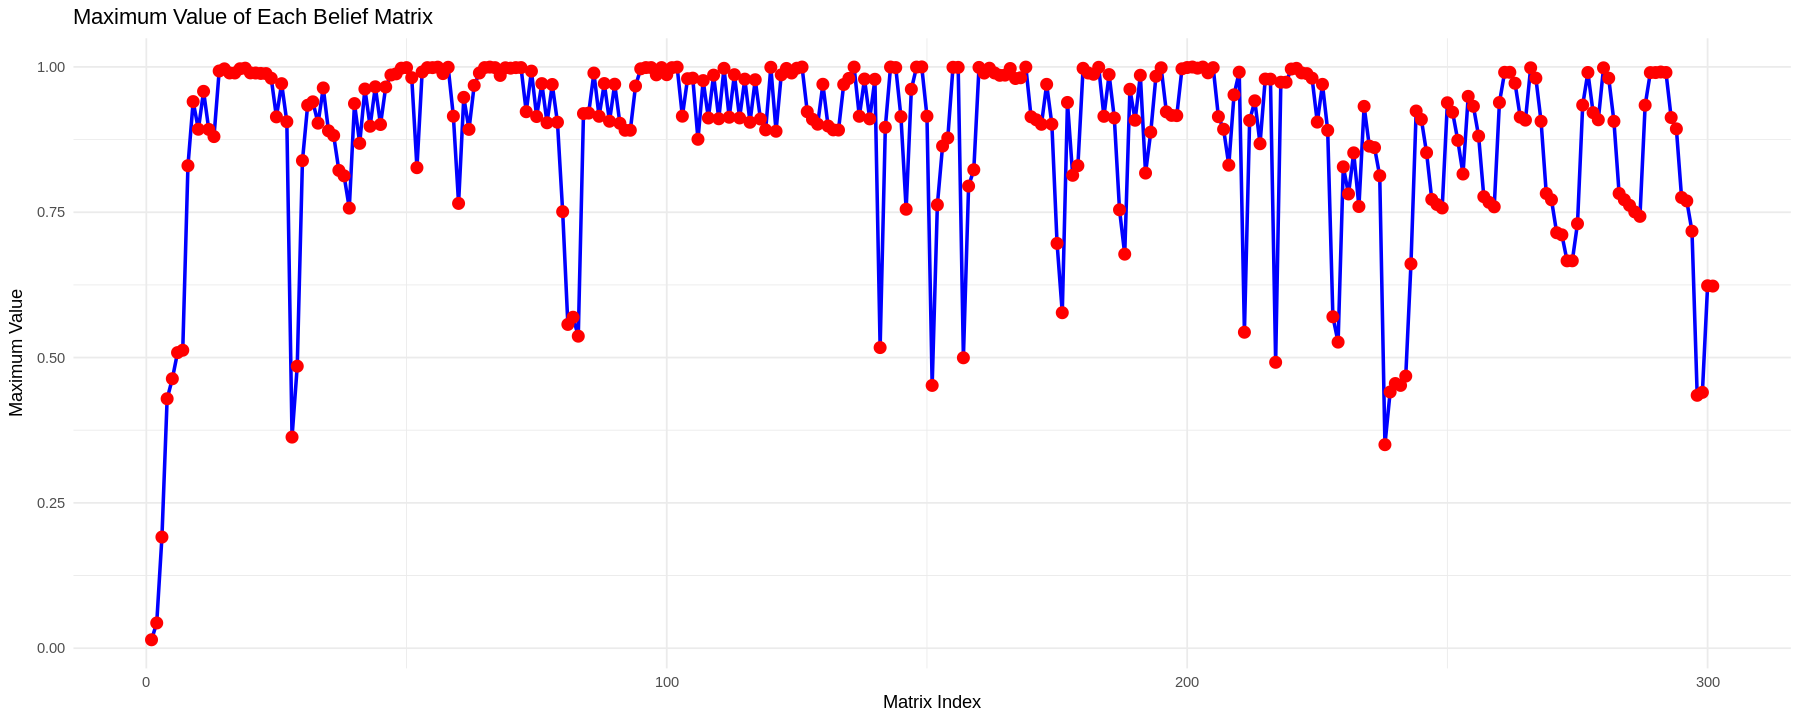

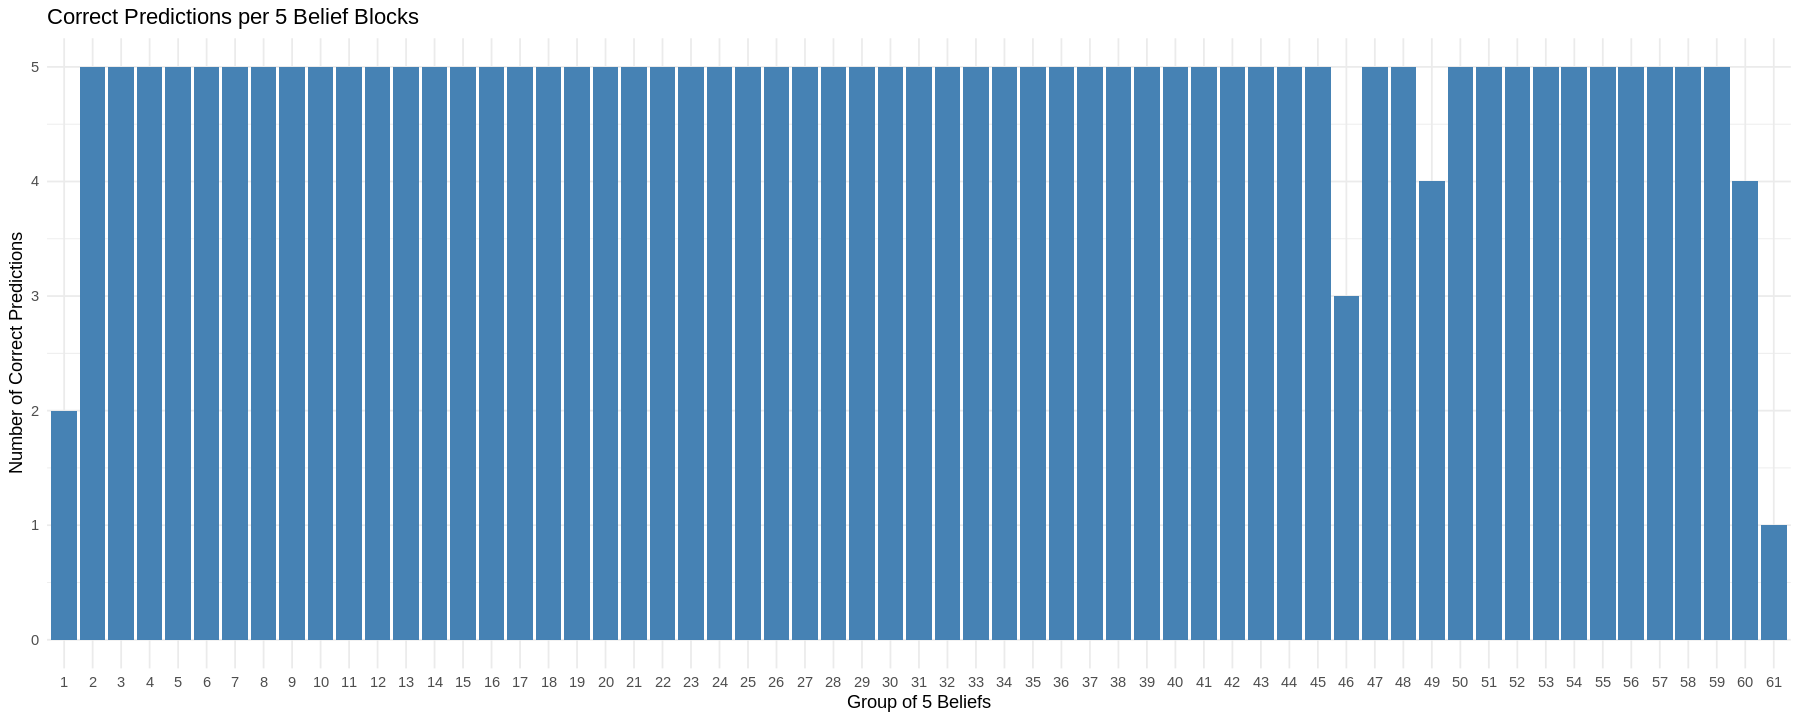

In [106]:
SENSOR_ERROR <- 0.01
MOVE_ERROR <- 0.01

result <- model(map, chosen_dirs)
beliefs <- result$beliefs
real_pos <- result$real_pos

plot_belief_maxima(beliefs)
plot_belief_accuracy(beliefs, real_pos)


Overall accuracy: 92.03%


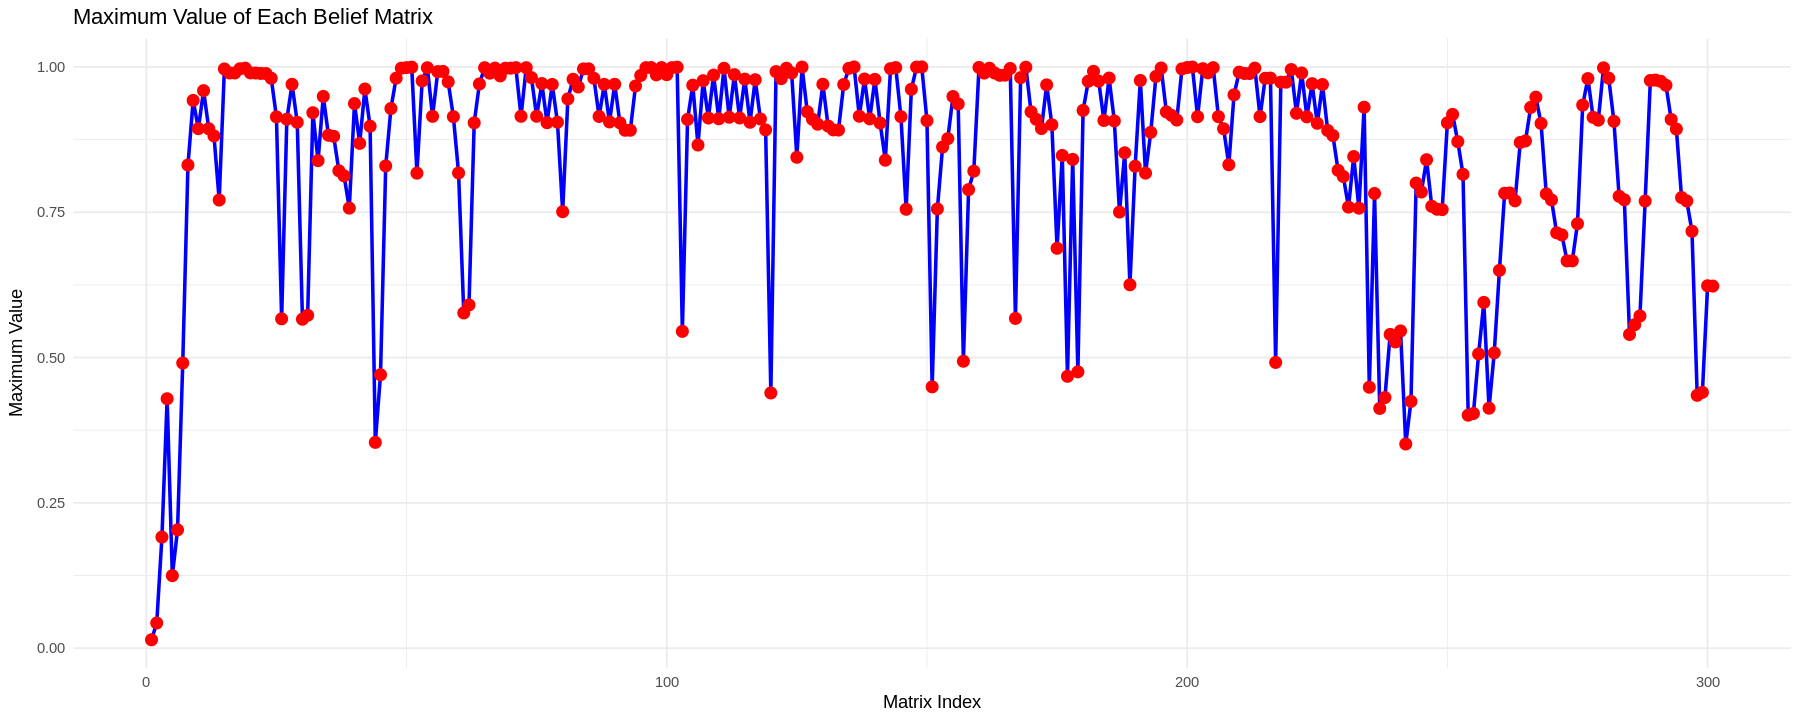

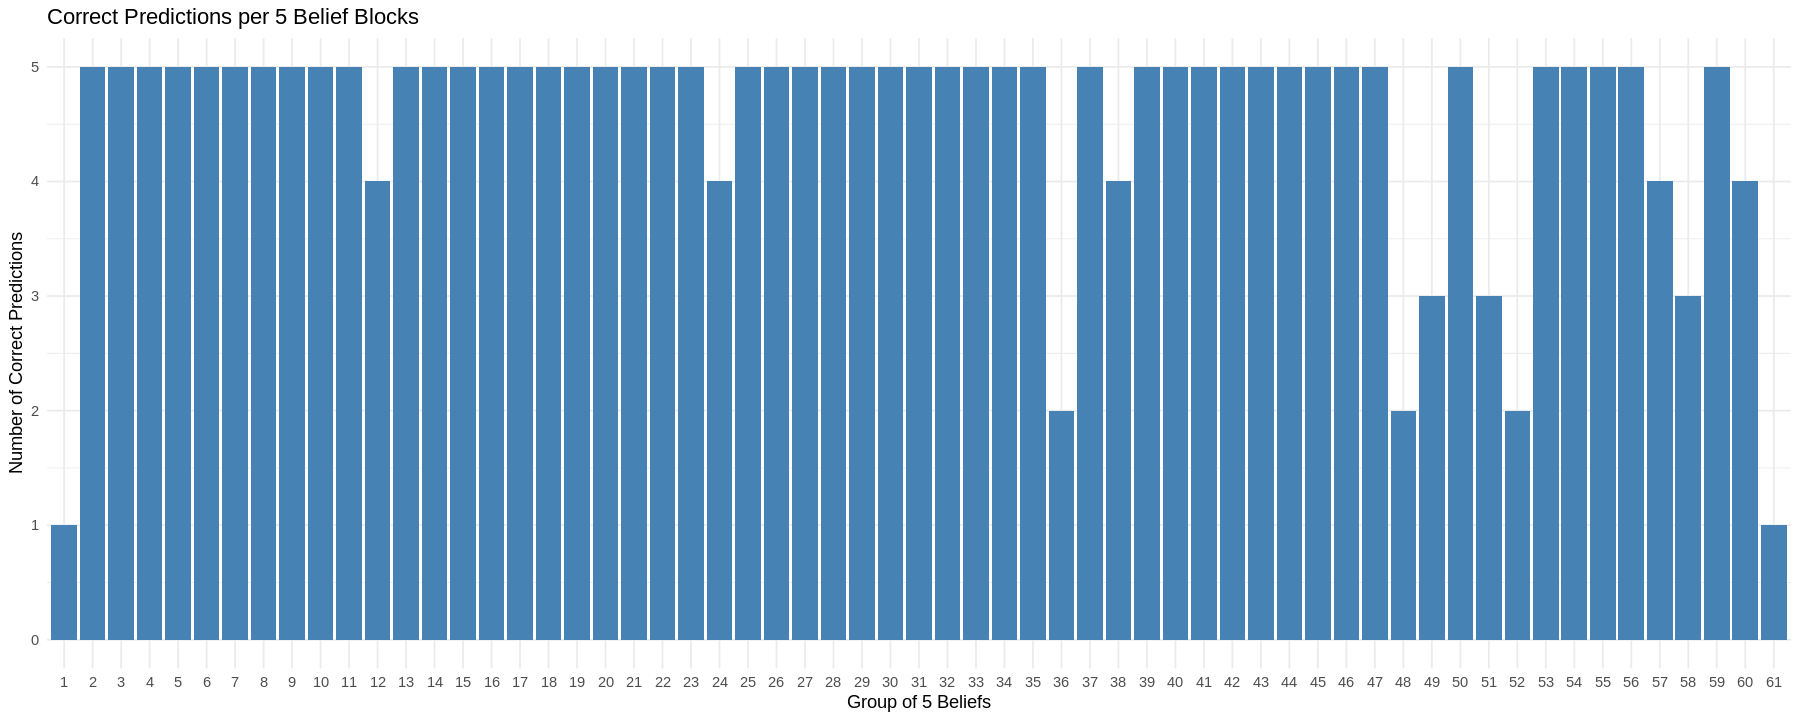

In [107]:
SENSOR_ERROR <- 0.05
MOVE_ERROR <- 0.05

result <- model(map, chosen_dirs)
beliefs <- result$beliefs
real_pos <- result$real_pos

plot_belief_maxima(beliefs)
plot_belief_accuracy(beliefs, real_pos)


Overall accuracy: 0.00%


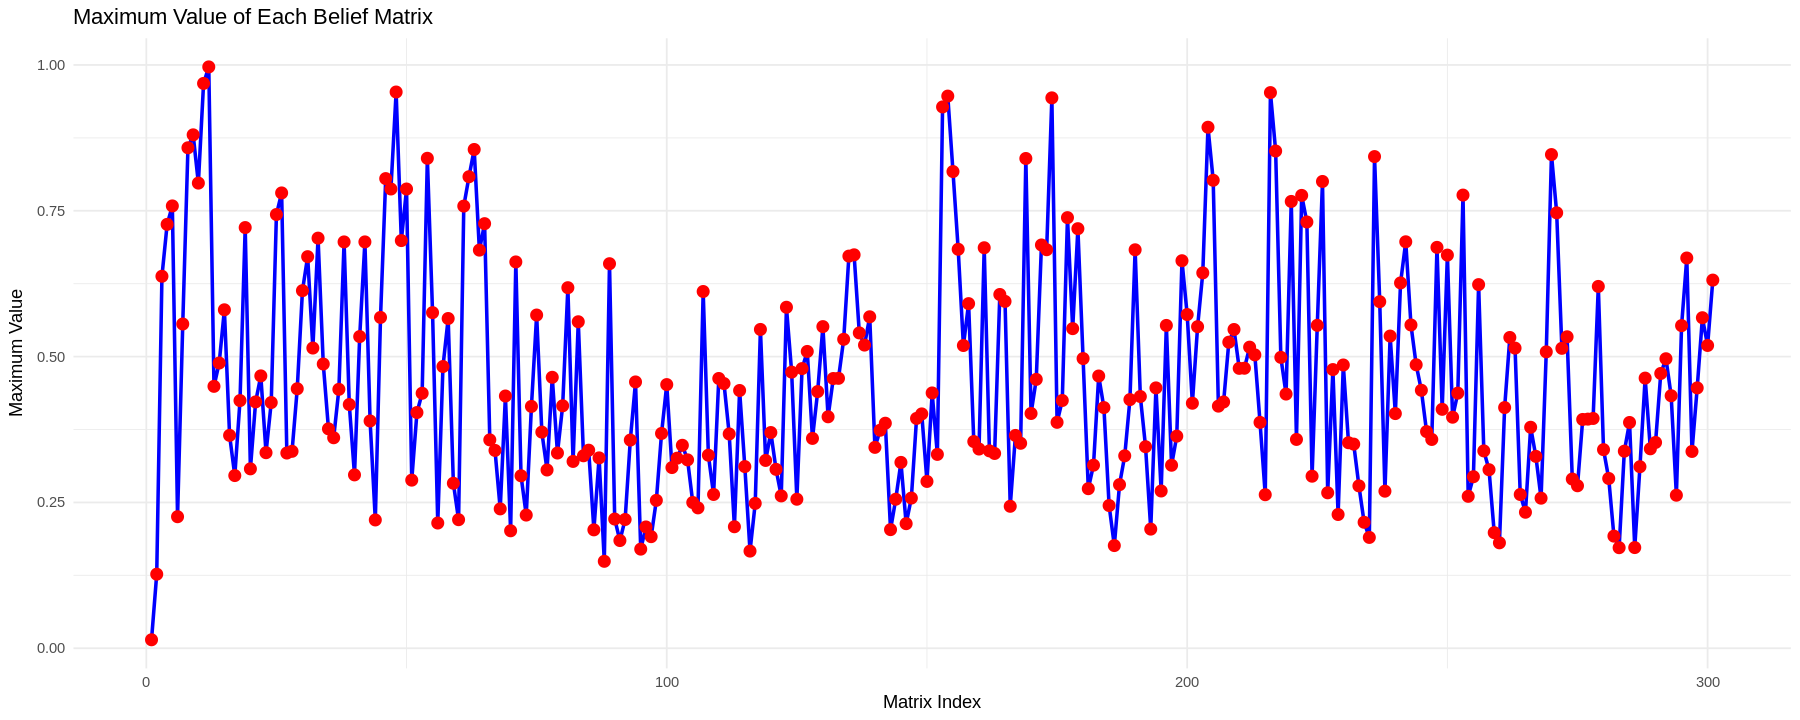

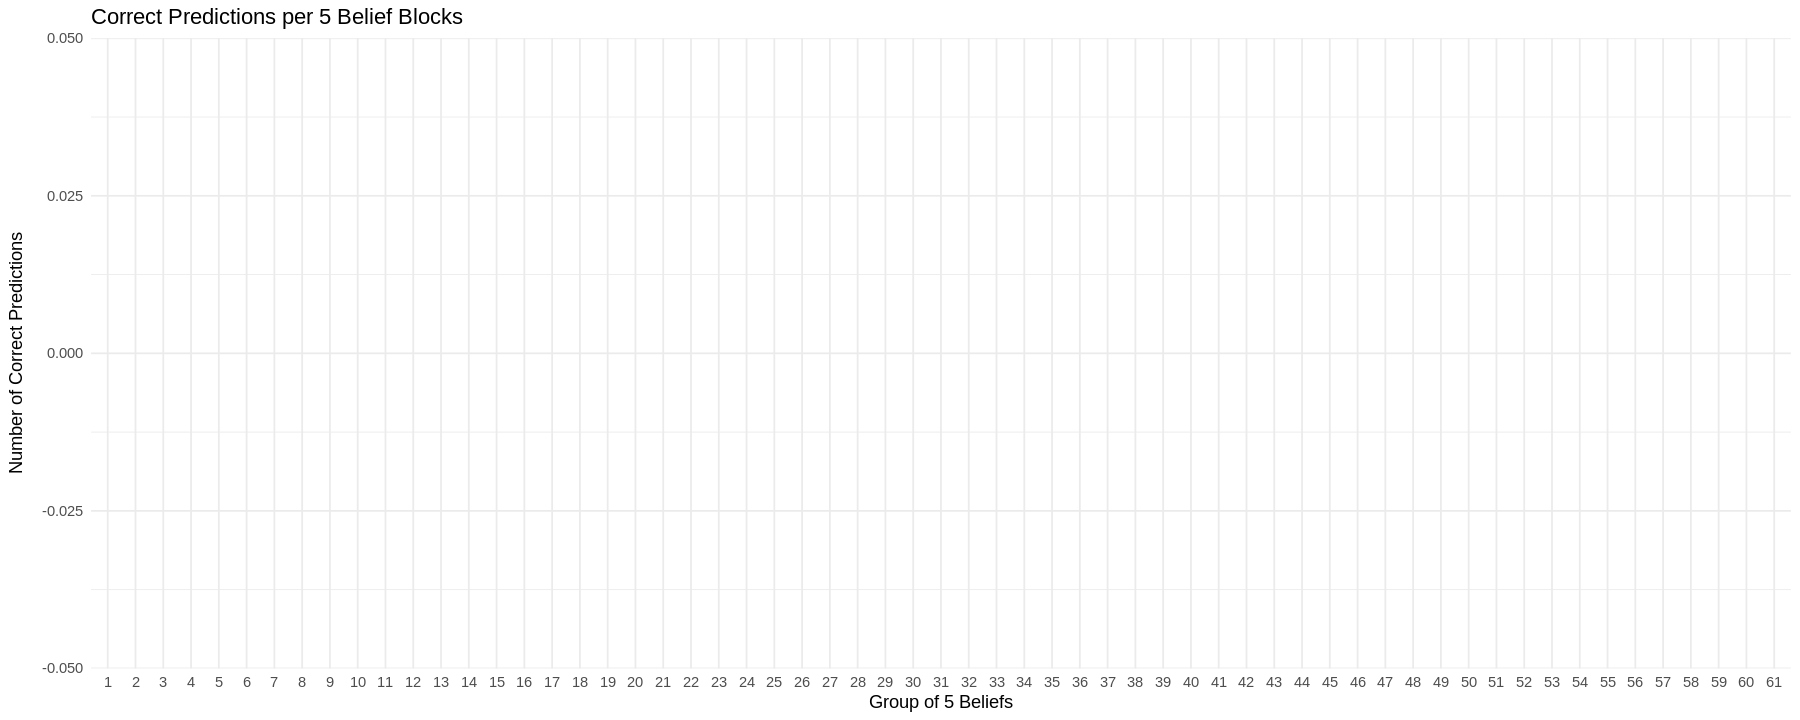

In [108]:
SENSOR_ERROR <- 0.6
MOVE_ERROR <- 0.6

result <- model(map, chosen_dirs)
beliefs <- result$beliefs
real_pos <- result$real_pos

plot_belief_maxima(beliefs)
plot_belief_accuracy(beliefs, real_pos)


Overall accuracy: 0.33%


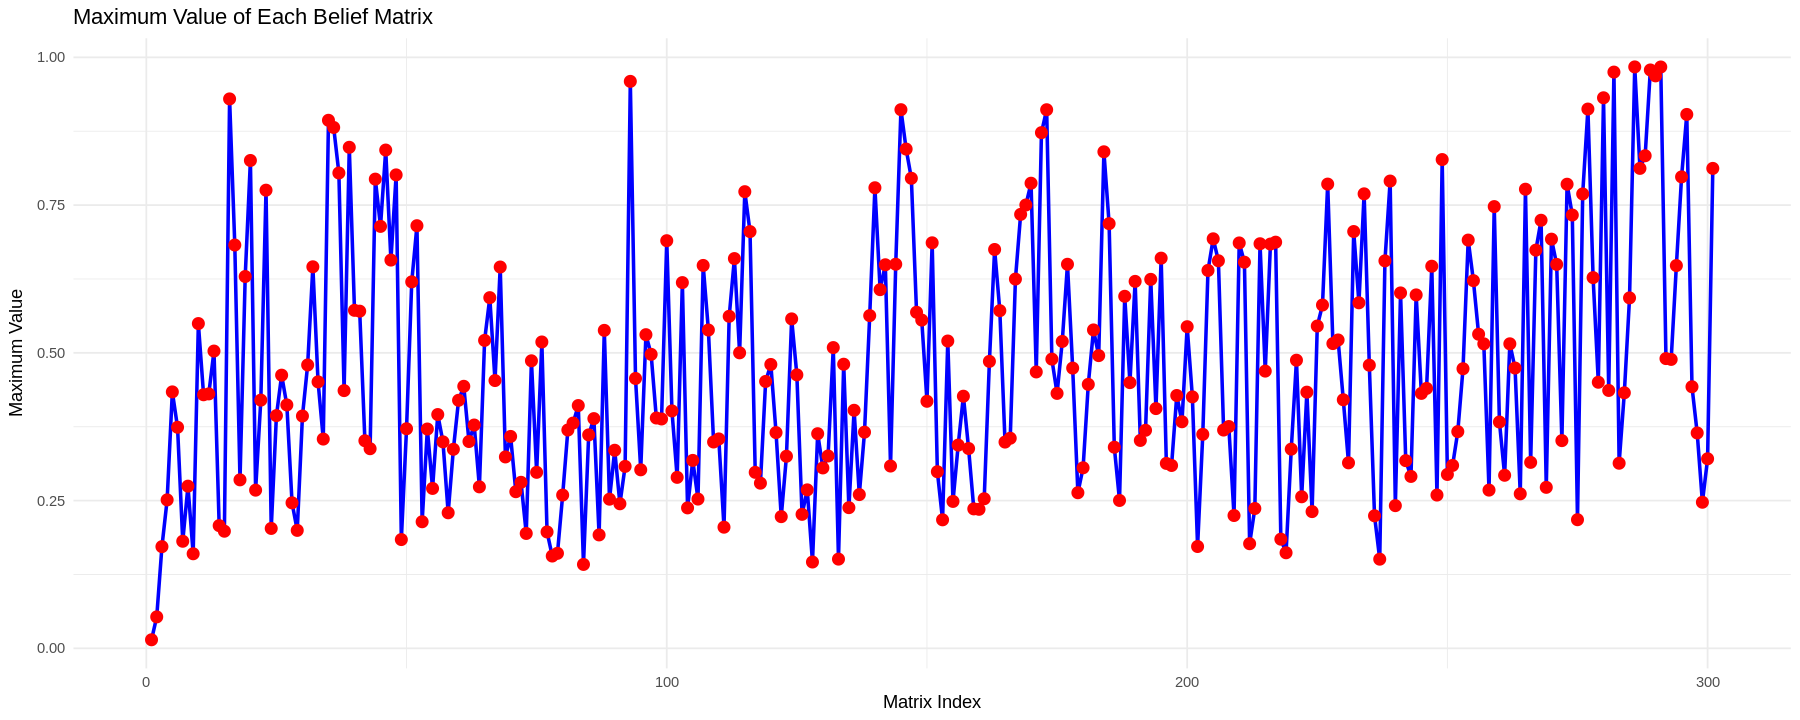

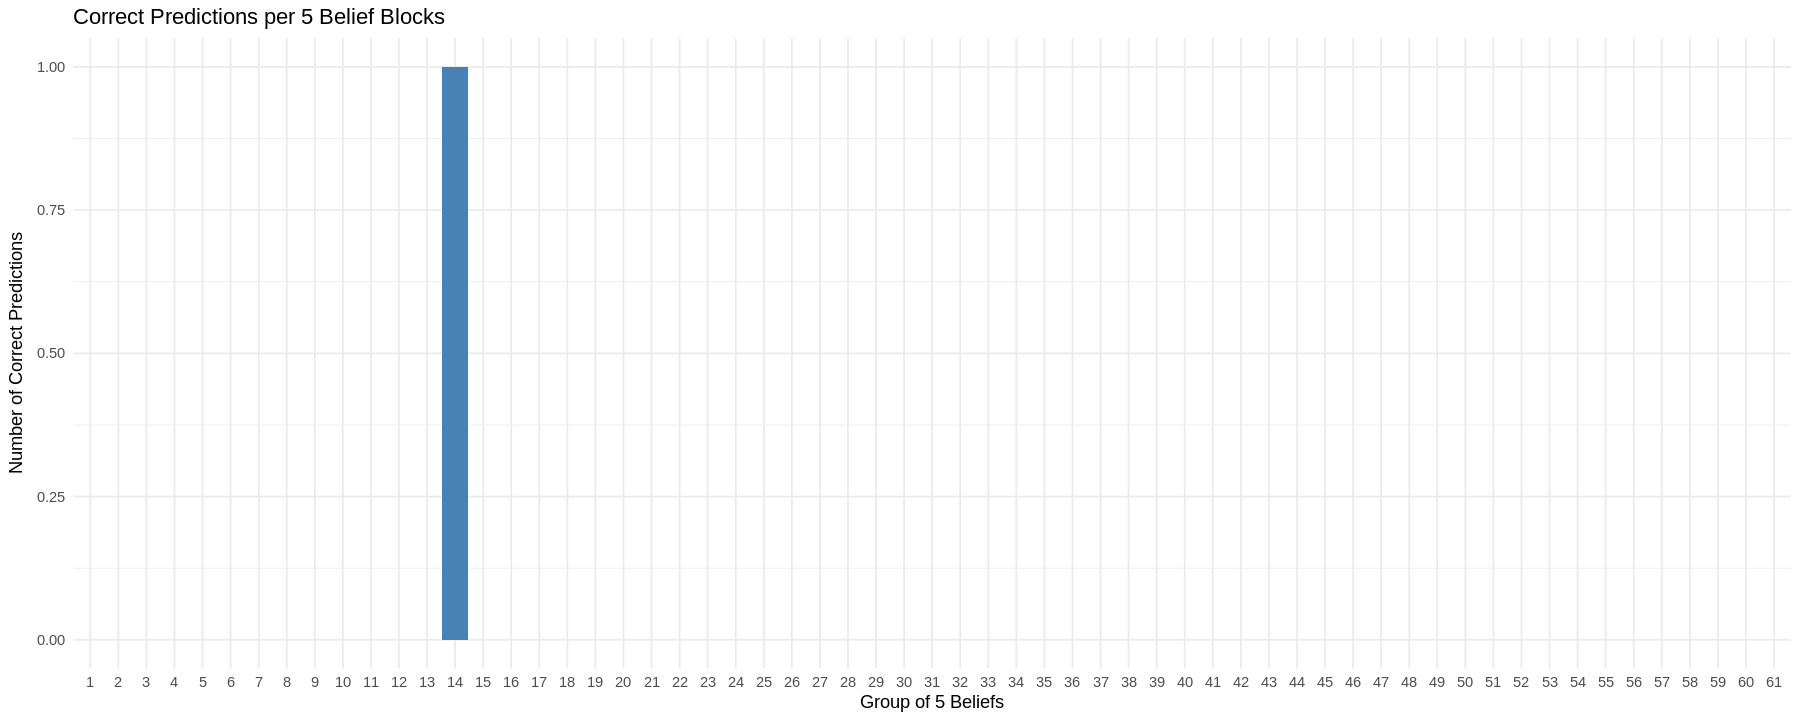

In [109]:
SENSOR_ERROR <- 0.6
MOVE_ERROR <- 0.001

result <- model(map, chosen_dirs)
beliefs <- result$beliefs
real_pos <- result$real_pos

plot_belief_maxima(beliefs)
plot_belief_accuracy(beliefs, real_pos)


Overall accuracy: 98.34%


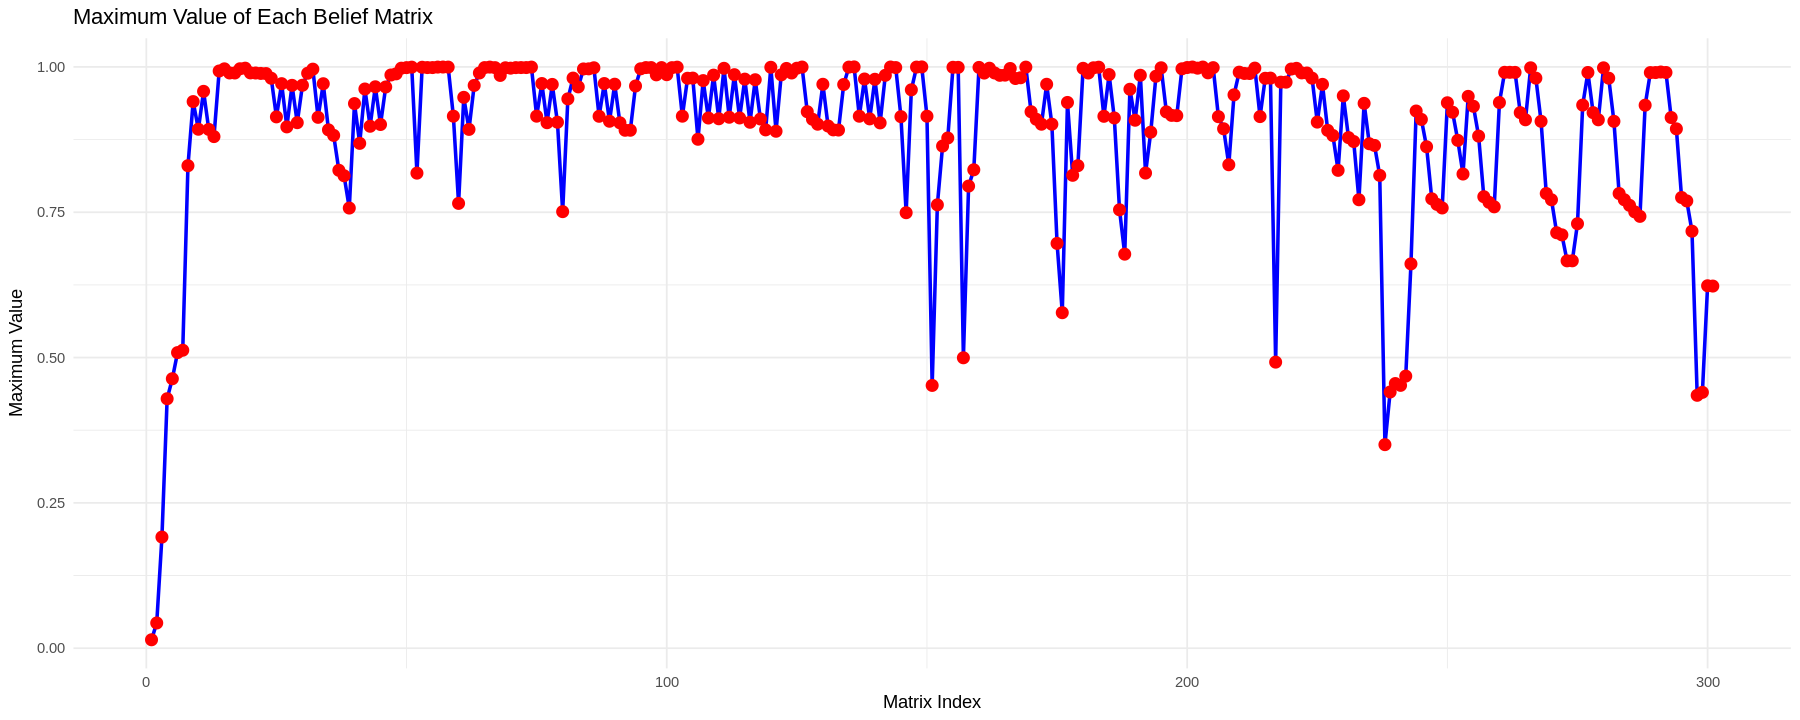

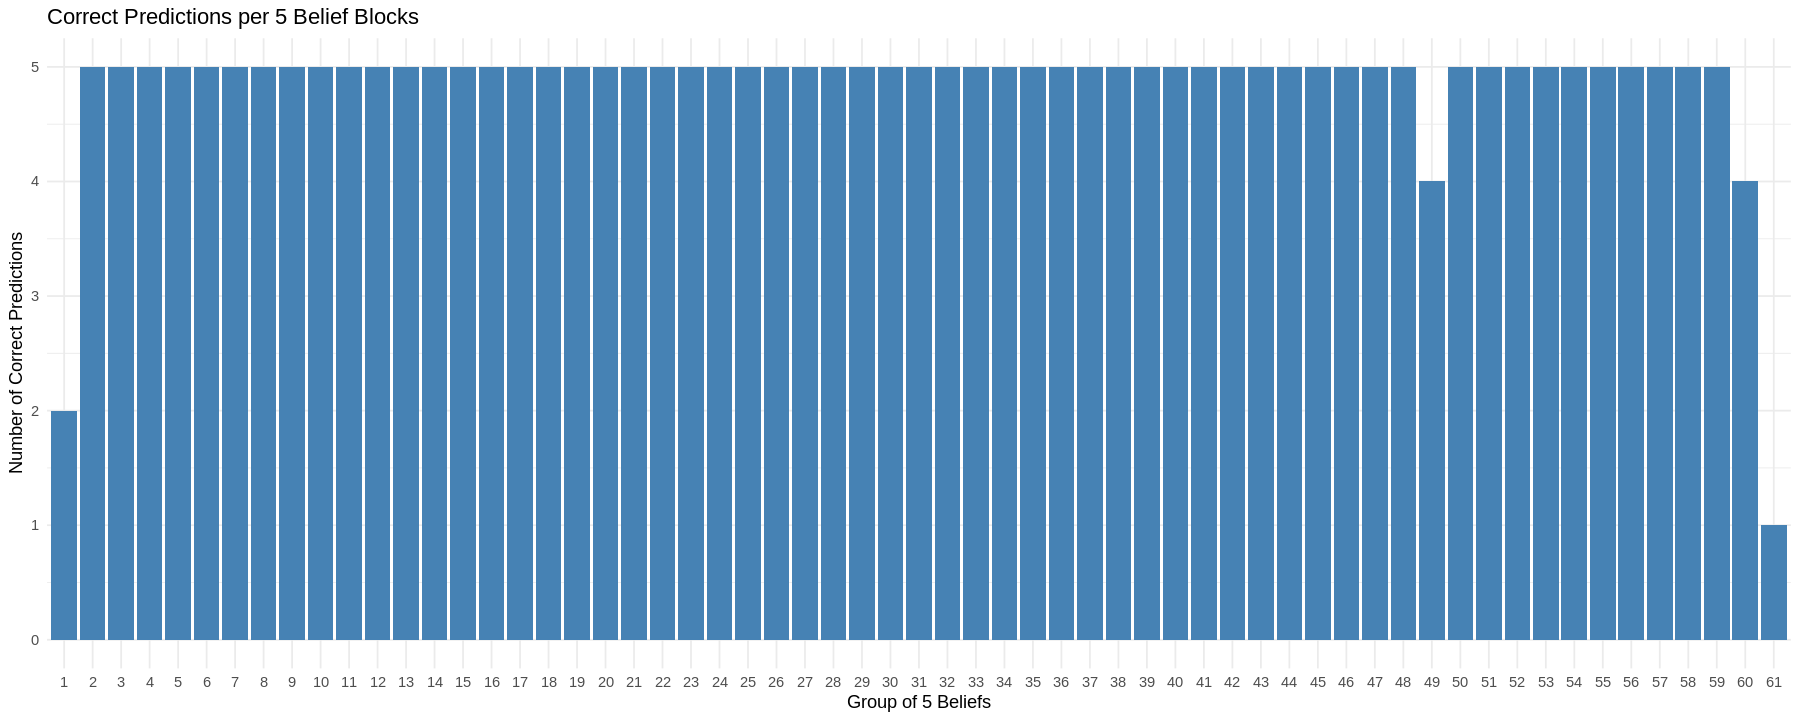

In [110]:
SENSOR_ERROR <- 0.001
MOVE_ERROR <- 0.6

result <- model(map, chosen_dirs)
beliefs <- result$beliefs
real_pos <- result$real_pos

plot_belief_maxima(beliefs)
plot_belief_accuracy(beliefs, real_pos)


🔴 **8.2
نتایج نشان می‌دهند که زمانی که خطای سنسور و خطای حرکت هر دو کوچک هستند، مدل به سرعت به موقعیت واقعی ربات همگرا می‌شود و دقت پیش‌بینی بالا است.

با افزایش هم‌زمان خطای سنسور و حرکت، باور مدل پخش‌تر می‌شود و بیشینه احتمال کاهش می‌یابد. در این حالت، مدل قادر نیست با اطمینان موقعیت ربات را تشخیص دهد.

زمانی که خطای سنسور زیاد و خطای حرکت کم است، مدل به دلیل دریافت اطلاعات نادرست از محیط دچار عدم قطعیت می‌شود، حتی اگر حرکت ربات تقریباً صحیح باشد.

در مقابل، زمانی که خطای حرکت زیاد و خطای سنسور کم است، با وجود مشاهدات دقیق، اختلاف بین مسیر واقعی و مسیر مورد انتظار باعث کاهش دقت کلی مدل می‌شود.

مقایسه نتایج نشان می‌دهد که خطای حرکت تأثیر مخرب‌تری بر دقت نهایی مدل دارد، زیرا این خطا در طول زمان تجمع پیدا می‌کند، در حالی که خطای سنسور تا حدی توسط اطلاعات جدید جبران می‌شود.
